# Predicting correctness with the correct answer hidden

The paper's model is told which answer is correct: its features compare the correct answer with
the wrong ones (`skip_rate__correct`, `num_label_visits__contrast`, ...). Here every one of the
paper's models gets versions that are not told. They see how the participant read the four
answers, named in one of three ways that need no answer key:

* **position** -- each answer by where it sat on screen (top, left, right, bottom). The positions
  are shuffled on every trial, and the correct answer sits in each one on about a quarter of the
  trials in both studies, so a position says nothing about correctness.
* **selected** -- the paper's own comparisons, with the answer the participant *selected* in place
  of the correct one: `skip_rate__selected`, `__unselected_mean`, `__selected_contrast`, ... Which
  answer was chosen is observed; whether it was right is not.
* **spread** -- each measure's largest, average and smallest value over the four answers: how
  attention was spread, with no answer singled out.

Everything that does not involve the answers -- the question, the presses, the sequence
statistics -- is the same in every version. All versions are scored by the paper's own
comparison, on the same folds and trials, so the gap to the paper's model is what knowing the
correct answer is worth.

**The slow steps run once.** The answer-hidden tables are saved beside the paper's
`model_ready.csv` and rebuilt only when what they are built from changes; the comparisons,
predictions, coefficients and searches are saved in `reports/_cache/answer_hidden/` and read
back while their feature sets, model and tables are the same (`cache.py`). After changing the
model or scoring code, pass `rerun=True`; after changing how the tables are built,
`load_tables(rebuild=True)`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; run.py's `main` saves

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import src.config.columns as Con
from src.modeling.models.logreg_model import imputed_cell_counts
from src.analyses.correctness_prediction.comparison import TESTS
from src.explorations.answer_hidden.table import NAMINGS, POSITION_AREAS, SELECTED_SUFFIXES, SPREAD_SUFFIXES
from src.explorations.answer_hidden.run import (
    load_tables, known_feature_sets, answer_free_feature_sets, model_order,
    run_answer_hidden_comparison, plot_answer_hidden_comparison,
    collect_predictions, plot_confusion_grid, plot_probability_grid, plot_probability_boxes, CONFUSION_TESTS,
    collect_answer_hidden_coefficients, plot_answer_hidden_coefficients,
)
from src.explorations.answer_hidden.deliberation import (
    DELIBERATION_GROUPS, SHORT_LIST, base_cols, combination_sets,
    run_deliberation_search, plot_search_heatmap, selected_feature_sets,
)
from src.explorations.answer_hidden.selected_features import SELECTED_FEATURES
from src.explorations.answer_hidden.discrimination import (
    discrimination_table, plot_discrimination, confidence_comparison, plot_confidence_roc,
)
from src.explorations.answer_hidden.matching import with_matching, matching_summary, matching_feature_sets
from src.explorations.answer_hidden.tracker import (
    NO_TRACKER_COLS, tracker_feature_sets, tracker_predictions, added_value_test, plot_added_value,
)

## 1. The table with the answers hidden
*`table.build_answer_hidden_table`*

One table holds all three namings. Columns that compare the correct answer with the wrong ones
are left out, and so are the paragraph features: the paragraph's parts are defined by the answer
key (the "critical" part holds the correct answer), and Study 2 has no paragraph screen anyway.

One trial's skip rate on the four answers, by letter as in the paper's table (`answer_A` is the
correct one), then the three ways it appears here. Answers with no value, such as the pupil size
on an answer never looked at, are skipped by the comparisons and the spread, as the paper's own
comparisons skip them.

In [2]:
tables = load_tables()
l1, l1_hidden = tables["l1"], tables["l1_hidden"]

trial = l1.iloc[[0]][[Con.PARTICIPANT_ID, Con.TRIAL_ID]]
row = l1_hidden.merge(trial)
display(l1.merge(trial)[[f"skip_rate__{a}" for a in Con.ANSWER_AREAS]])
for suffixes in (POSITION_AREAS, SELECTED_SUFFIXES, SPREAD_SUFFIXES):
    display(row[[f"skip_rate__{s}" for s in suffixes]])

KnowQA showcase frame: 1885 trials x 201 columns
  participants : 13
  sessions     : 39
  regimes      : {'full knowledge': 640, 'no knowledge': 625, 'partial knowledge': 620}
l1: reading the answer-hidden table from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\l1_onestop\features\answer_hidden.csv
knowqa: reading the answer-hidden table from E:\Technion\QA PROJECT\programming\QA_eyetracking_workspace\data\datasets\knowqa\features\answer_hidden.csv


,skip_rate__answer_A,skip_rate__answer_B,skip_rate__answer_C,skip_rate__answer_D
0,0.25,0.428571,0.571429,0.428571


,skip_rate__answer_0(top),skip_rate__answer_1(left),skip_rate__answer_2(right),skip_rate__answer_3(bottom)
0,0.428571,0.571429,0.428571,0.25


,skip_rate__selected,skip_rate__unselected_mean,skip_rate__selected_contrast,skip_rate__selected_distance_furthest,skip_rate__selected_distance_closest
0,0.25,0.47619,-0.22619,0.321429,0.178571


,skip_rate__answer_max,skip_rate__answer_mean,skip_rate__answer_min
0,0.571429,0.419643,0.25


### The feature sets

Each of the paper's sets becomes its answer-free versions by one rule per naming
(`table.hide_answers`):

* **position**: a feature of the correct answer, the wrong ones, or the comparison between them
  becomes the same measure at each of the four positions;
* **selected**: each comparison becomes the same comparison with the selected answer
  (`__correct` to `__selected`, `__wrong_mean` to `__unselected_mean`, ...), so the set keeps
  its size, and "the last look was at the correct answer" becomes "at the selected answer";
* **spread**: a feature of the answers becomes the measure's largest, average and smallest value
  over the four; the last look at an answer has no such version and is left out.

The question's and the answers' shares of looking time add up to 1, so a share that the others
fix is left out. `all_features` is every feature in the paper's table except the opening-scan
features (which summarise a person over several trials, and which the comparison refuses) and
the paragraph ones.

In [3]:
known = known_feature_sets(l1)
free = answer_free_feature_sets(known)
display(pd.DataFrame({"features": {n: len(c) for n, c in {**known, **free}.items()}}).loc[model_order(known)])
pd.DataFrame({by: pd.Series(free[f"select_1_{by}"]) for by in NAMINGS})

,features
select_1,10
select_1_position,23
select_1_selected,10
select_1_spread,18
select_1_plus_last_confirm,12
select_1_plus_last_confirm_position,27
select_1_plus_last_confirm_selected,12
select_1_plus_last_confirm_spread,19
all_features,174
all_features_position,93


,position,selected,spread
0,area_dwell_proportion__answer_0(top),area_dwell_proportion__selected,area_dwell_proportion__answer_max
1,area_dwell_proportion__answer_1(left),area_dwell_proportion__question,area_dwell_proportion__answer_min
2,area_dwell_proportion__answer_2(right),skip_rate__selected,area_dwell_proportion__question
3,area_dwell_proportion__question,has_xyx,skip_rate__answer_max
4,skip_rate__answer_0(top),ANSWER_PRESS_NUMBER,skip_rate__answer_mean
5,skip_rate__answer_1(left),num_label_visits__selected,skip_rate__answer_min
6,skip_rate__answer_2(right),num_label_visits__selected_contrast,has_xyx
7,skip_rate__answer_3(bottom),mean_fixations_count__question,ANSWER_PRESS_NUMBER
8,has_xyx,mean_fixations_count__unselected_mean,num_label_visits__answer_max
9,ANSWER_PRESS_NUMBER,mean_max_fix_pupil_size_z__selected,num_label_visits__answer_mean


### One way the answer key can still get in

The *selected* versions measure the chosen answer, and the answers differ in length. On its own,
the selected answer's length predicts correctness a little above chance (a balanced accuracy of
about 0.53 on Study 1 and 0.55 on Study 2, from the length, the length relative to the other
answers and its rank). A measure that grows with an answer's length, such as its share of looking
time, can carry some of that. The *position* and *spread* versions single out no answer, so they
cannot.

### Filled-in values

The model fills every missing value with 0. In the paper's model that touches one feature, the
pupil size on the correct answer, missing when it was never looked at. Here the count depends on
the naming: the pupil size at every position is missing whenever that answer went unread, while
the largest over the four is missing only when no answer was looked at. Per set, on Study 1:

In [4]:
for name in model_order({"select_1_plus_last_confirm": None}):
    cols = (known | free)[name]
    counts = imputed_cell_counts(tables["l1" if name in known else "l1_hidden"], cols)
    print(f"{name}: {counts.sum()} cells = {100 * counts.sum() / (len(l1) * len(cols)):.2f}% of the matrix")

select_1_plus_last_confirm: 253 cells = 0.11% of the matrix
select_1_plus_last_confirm_position: 2651 cells = 0.51% of the matrix
select_1_plus_last_confirm_selected: 187 cells = 0.08% of the matrix
select_1_plus_last_confirm_spread: 84 cells = 0.02% of the matrix


## 2. Known against hidden, on both studies
*`run.run_answer_hidden_comparison`, `run.plot_answer_hidden_comparison`*

Each paper model is followed by its three answer-free versions. Study 1 is the paper's ten-fold
cross-validation: a panel for each kind of held-out trial (a new paragraph, a new participant, or
both) and one for their average, with the interval across folds. Study 2 is one fit on every
Study 1 trial, scored on each knowledge regime and on all of them together; one fit and one test
set, so no interval. Bars start at chance (0.5). Takes a few minutes.

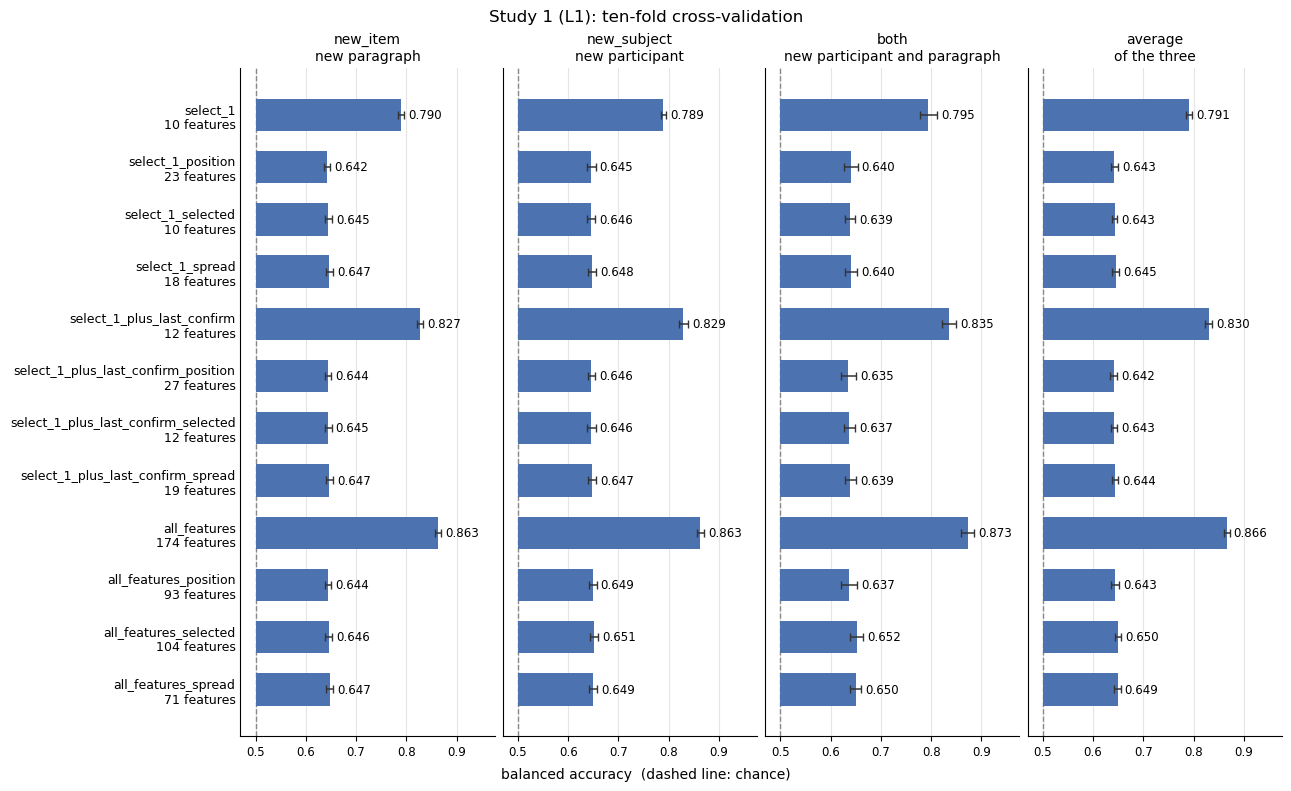

test,new_item,new_subject,both,average
model,,,,
select_1,0.790,0.789,0.795,0.791
select_1_position,0.642,0.645,0.640,0.643
select_1_selected,0.645,0.646,0.639,0.643
select_1_spread,0.647,0.648,0.640,0.645
select_1_plus_last_confirm,0.827,0.829,0.835,0.830
select_1_plus_last_confirm_position,0.644,0.646,0.635,0.642
select_1_plus_last_confirm_selected,0.645,0.646,0.637,0.643
select_1_plus_last_confirm_spread,0.647,0.647,0.639,0.644
all_features,0.863,0.863,0.873,0.866


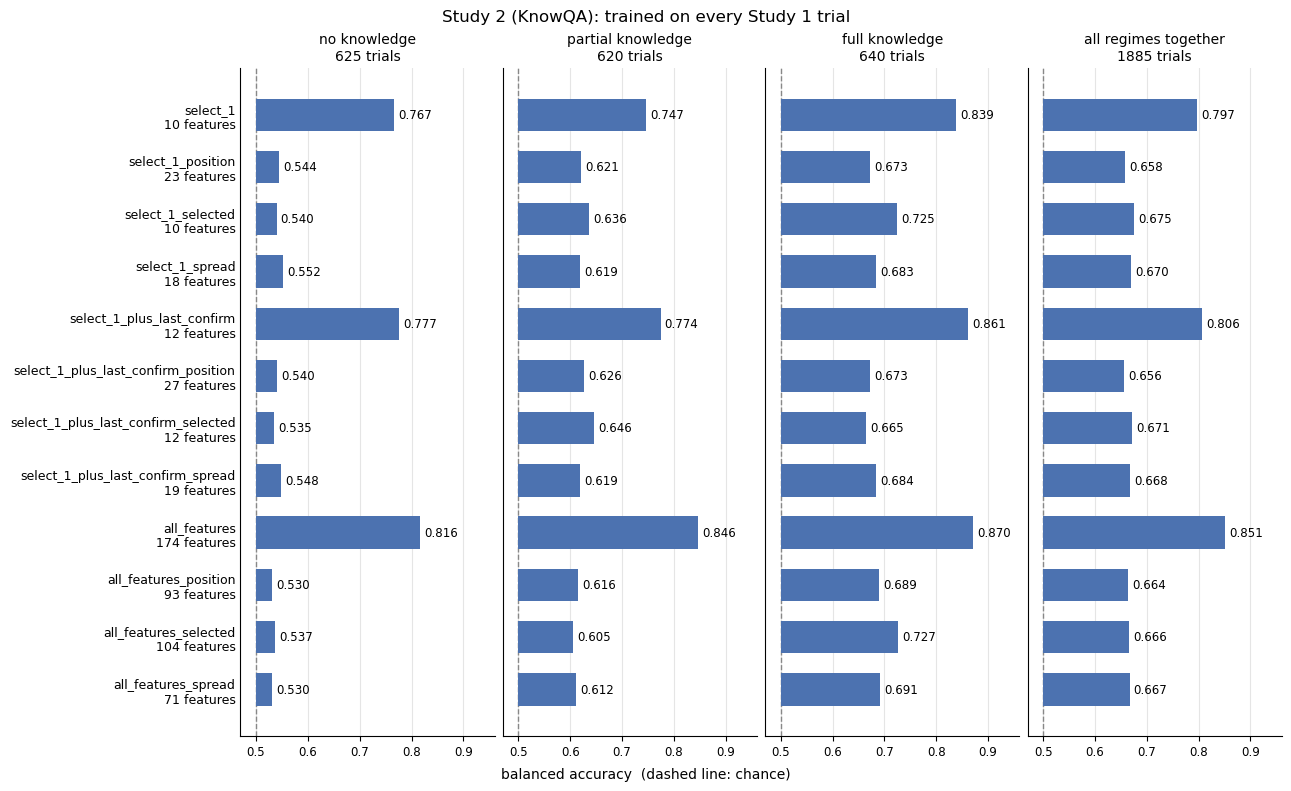

test,no knowledge,partial knowledge,full knowledge,all
model,,,,
select_1,0.767,0.747,0.839,0.797
select_1_position,0.544,0.621,0.673,0.658
select_1_selected,0.540,0.636,0.725,0.675
select_1_spread,0.552,0.619,0.683,0.670
select_1_plus_last_confirm,0.777,0.774,0.861,0.806
select_1_plus_last_confirm_position,0.540,0.626,0.673,0.656
select_1_plus_last_confirm_selected,0.535,0.646,0.665,0.671
select_1_plus_last_confirm_spread,0.548,0.619,0.684,0.668
all_features,0.816,0.846,0.870,0.851


In [5]:
comparison = run_answer_hidden_comparison(tables, known, verbose=False)
scores = comparison["scores"]
for ds in TESTS:   # "l1", then "knowqa"
    plot_answer_hidden_comparison(comparison, dataset=ds, models=model_order(known))
    plt.show()
    display(scores[scores["dataset"] == ds]
            .pivot(index="model", columns="test", values="balanced_accuracy")
            .loc[model_order(known), TESTS[ds]]
            .round(3))

## 3. Where each version goes wrong
*`run.collect_predictions`, `run.plot_confusion_grid`*

The confusion matrix of every version, one grid per test: a row per paper model, a column per
version. Each cell gives the count and, below it, its share of the row's actual outcome, and is
shaded by that share, so the grids compare across versions whatever the accuracy. The two
diagonal shares are the specificity (top left: wrong answers called wrong) and the sensitivity
(bottom right: right answers called right); each title gives their mean, the balanced accuracy.

The predictions are the ones the scores above come from. On Study 1, the held-out trials of all
ten folds, pooled. A trial can be held out in more than one fold, so the counts are of
predictions, not trials, and a title's balanced accuracy can differ from the comparison's by a
few thousandths, since that one is the mean of the ten folds' own scores. On Study 2, the one fit
on Study 1, scored on each regime and on all of them together; these match the comparison
exactly. Runs the cross-validation again: about a minute and a half.

[cache] predictions: read predictions__f19c189784e7.pkl


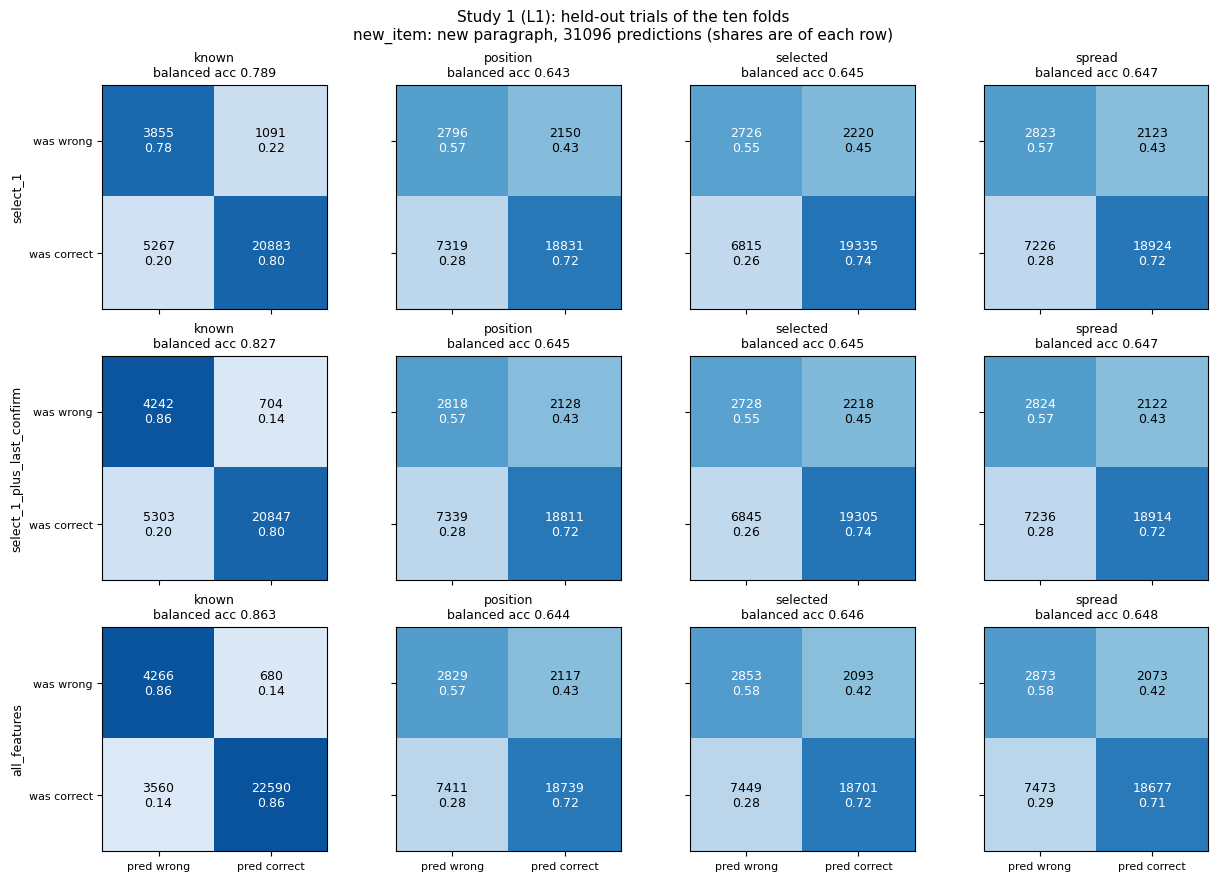

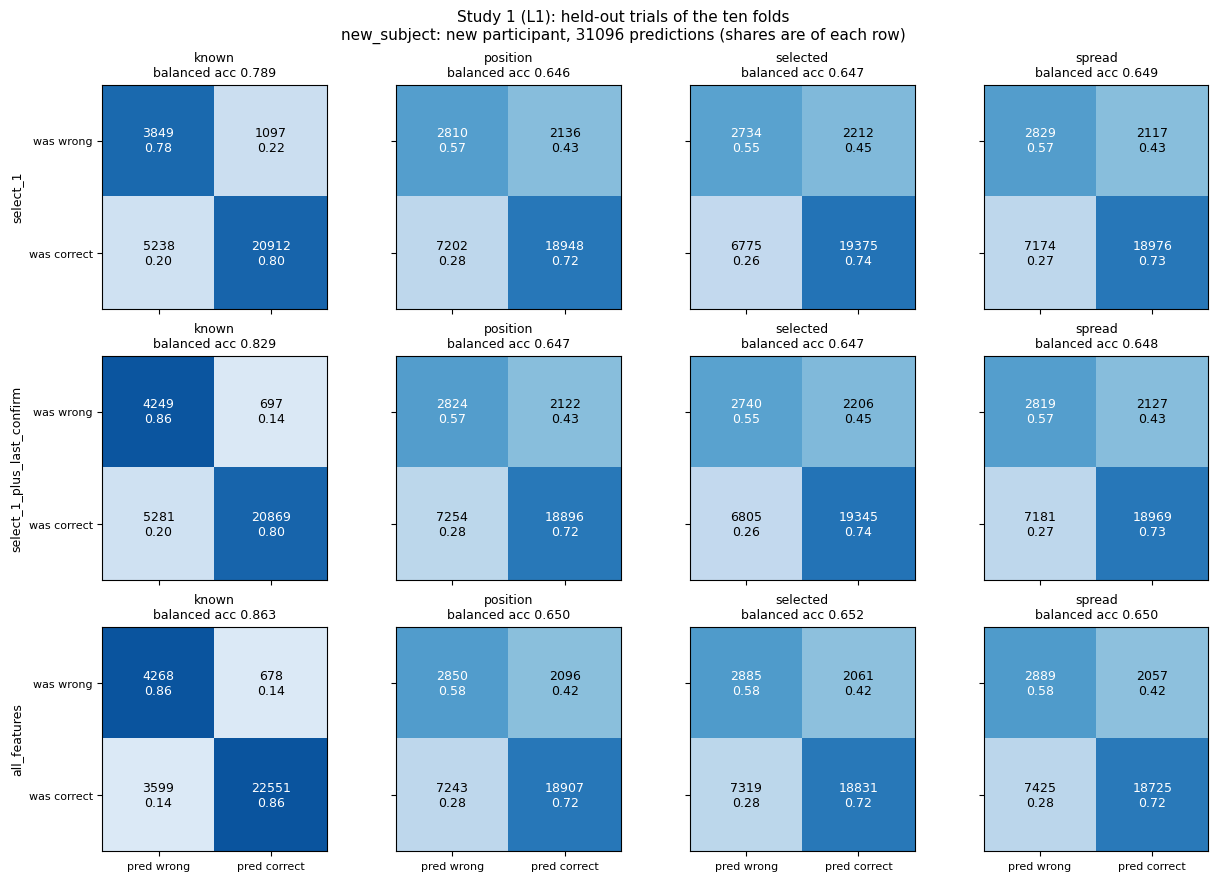

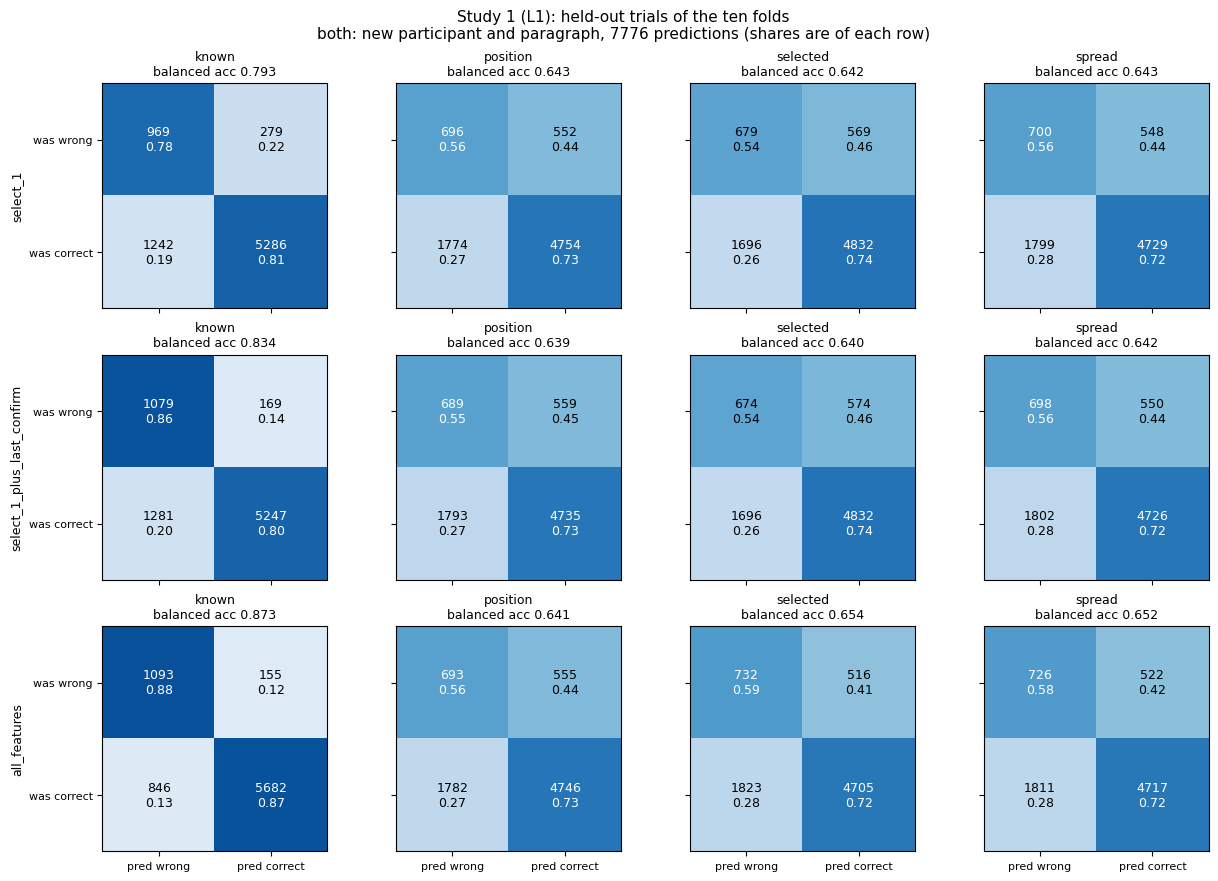

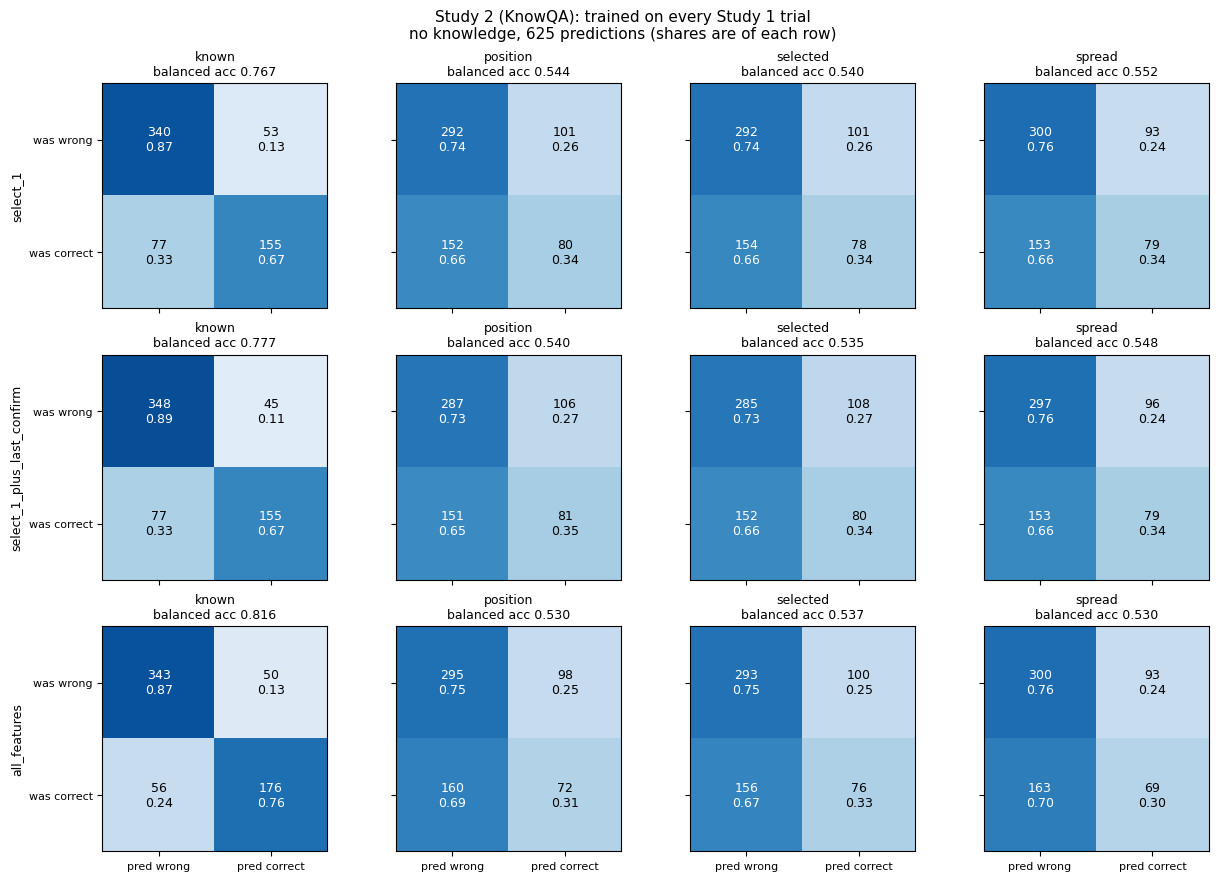

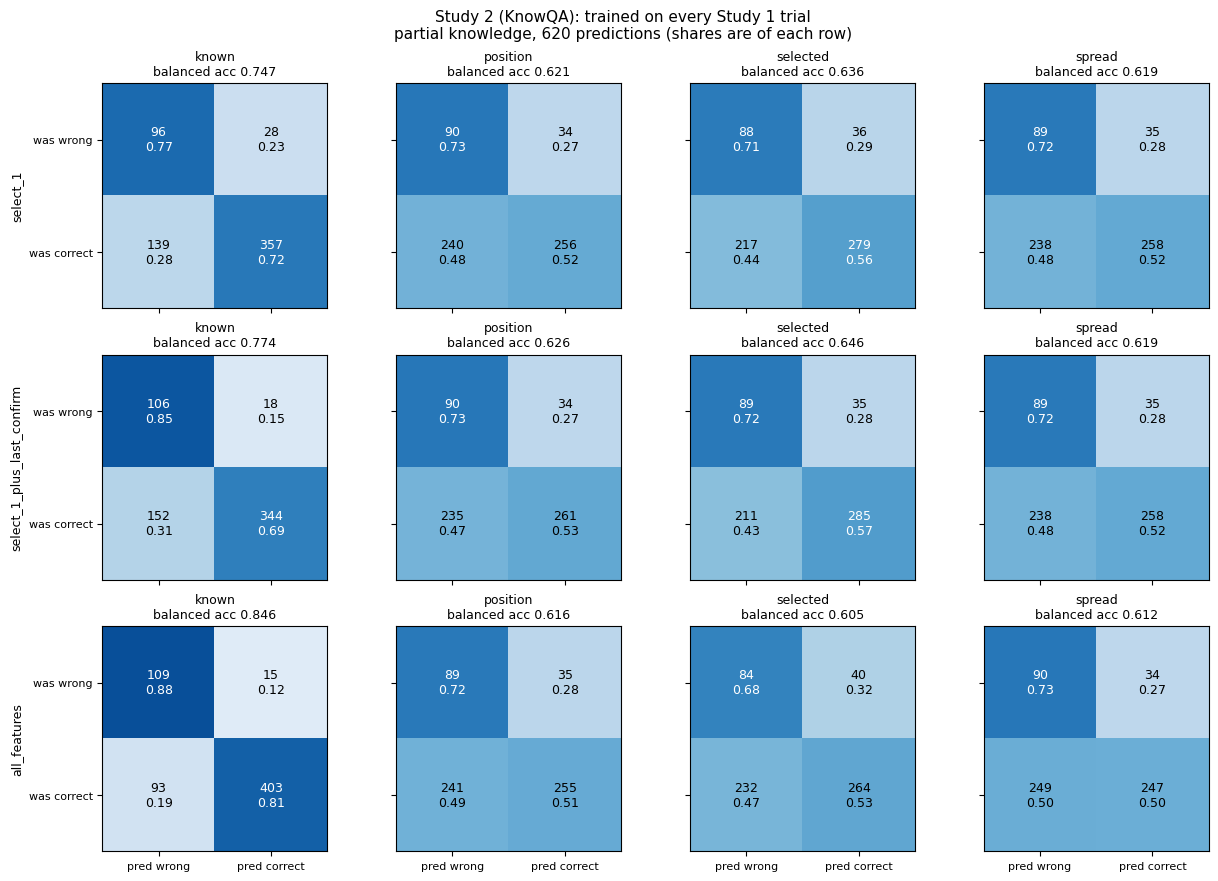

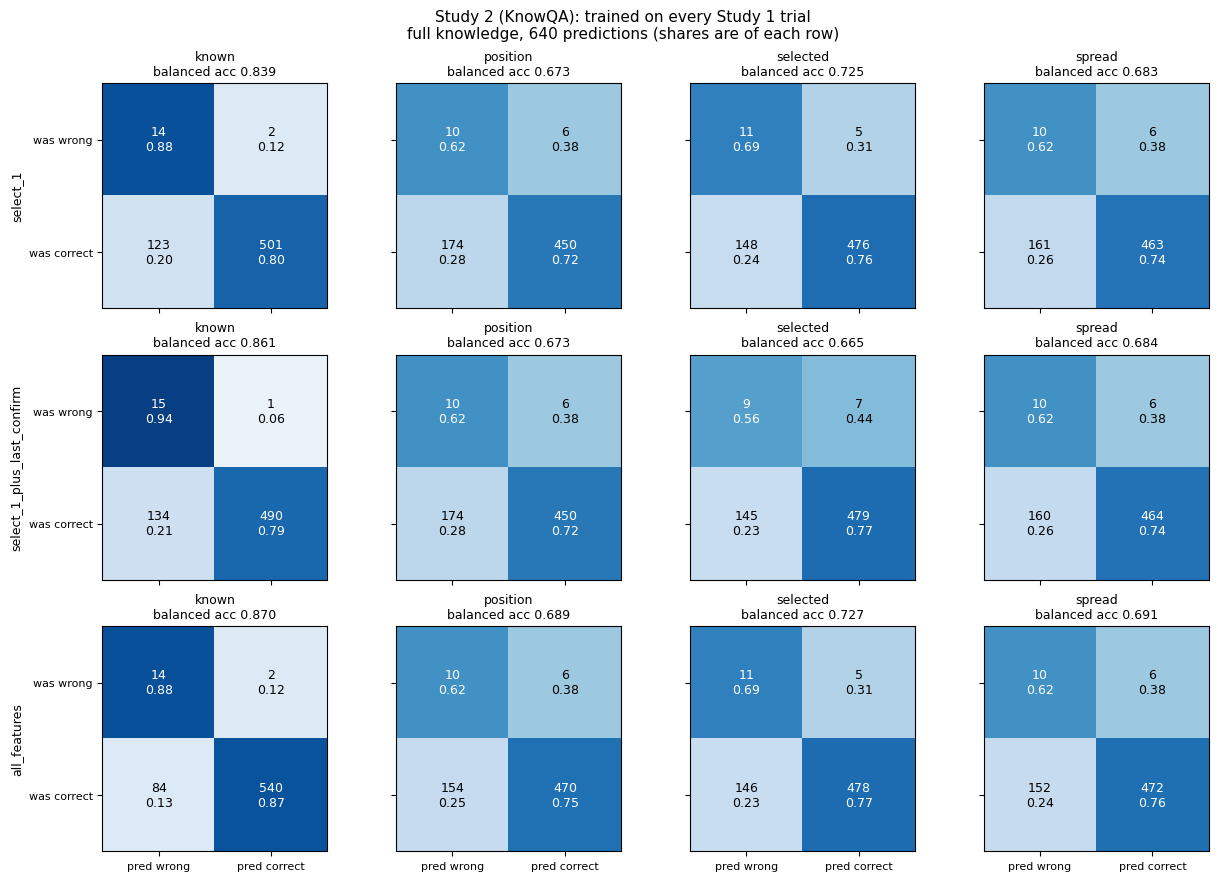

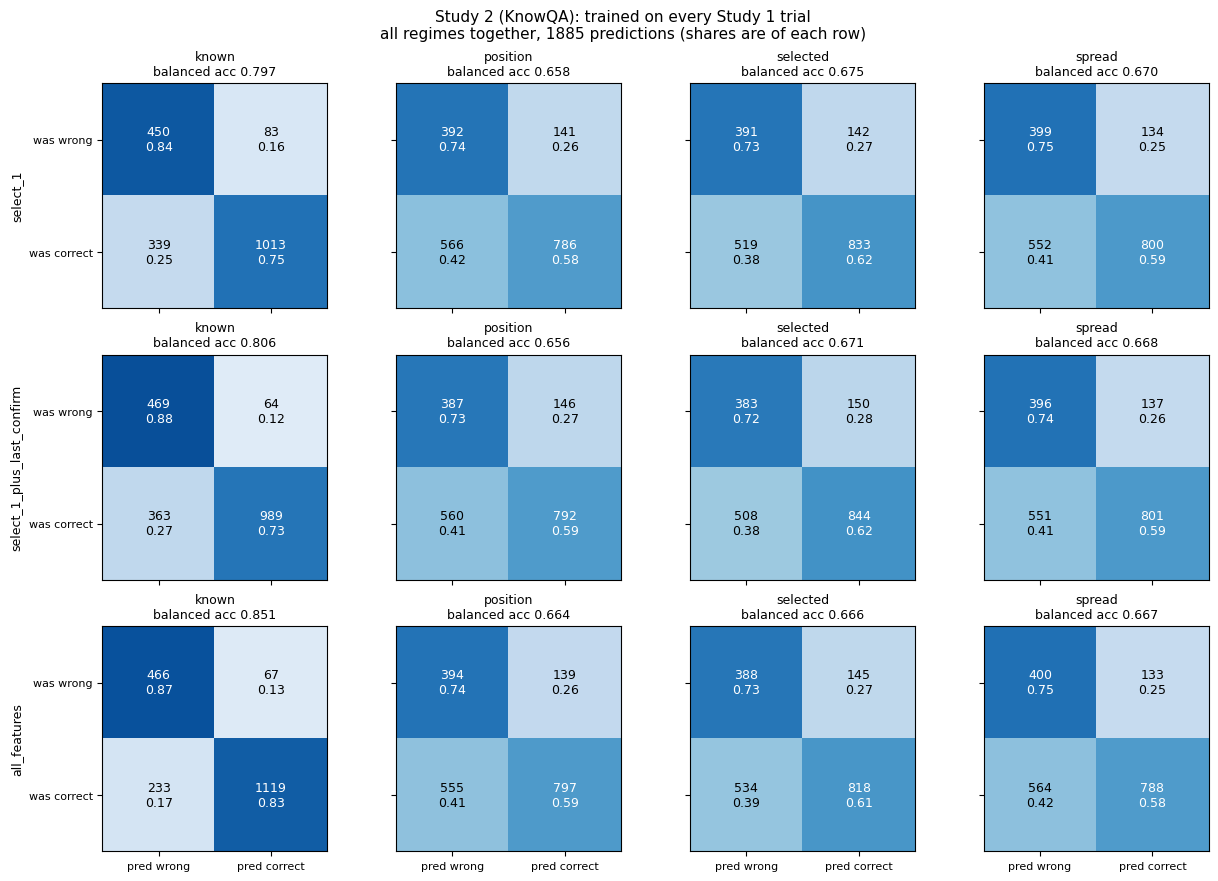

In [6]:
preds = collect_predictions(tables, known)
for ds, tests in CONFUSION_TESTS.items():   # Study 1's three held-out kinds, then Study 2's regimes and all together
    for test in tests:
        plot_confusion_grid(preds, dataset=ds, test=test)
        plt.show()

### Predicted probabilities, by outcome
*`run.plot_probability_grid`*

The same predictions as histograms of P(correct), split into answers that were right (blue) and
wrong (red), as in the Study 2 overview: one figure per paper model and study, a row per version,
a column per test, the dashed line the panel's mean. Each panel asks whether the two humps sit in
different places, that is, whether the version tells right from wrong answers apart within that
test rather than only following its base rate. On Study 1 the counts are of predictions pooled
over the ten folds.

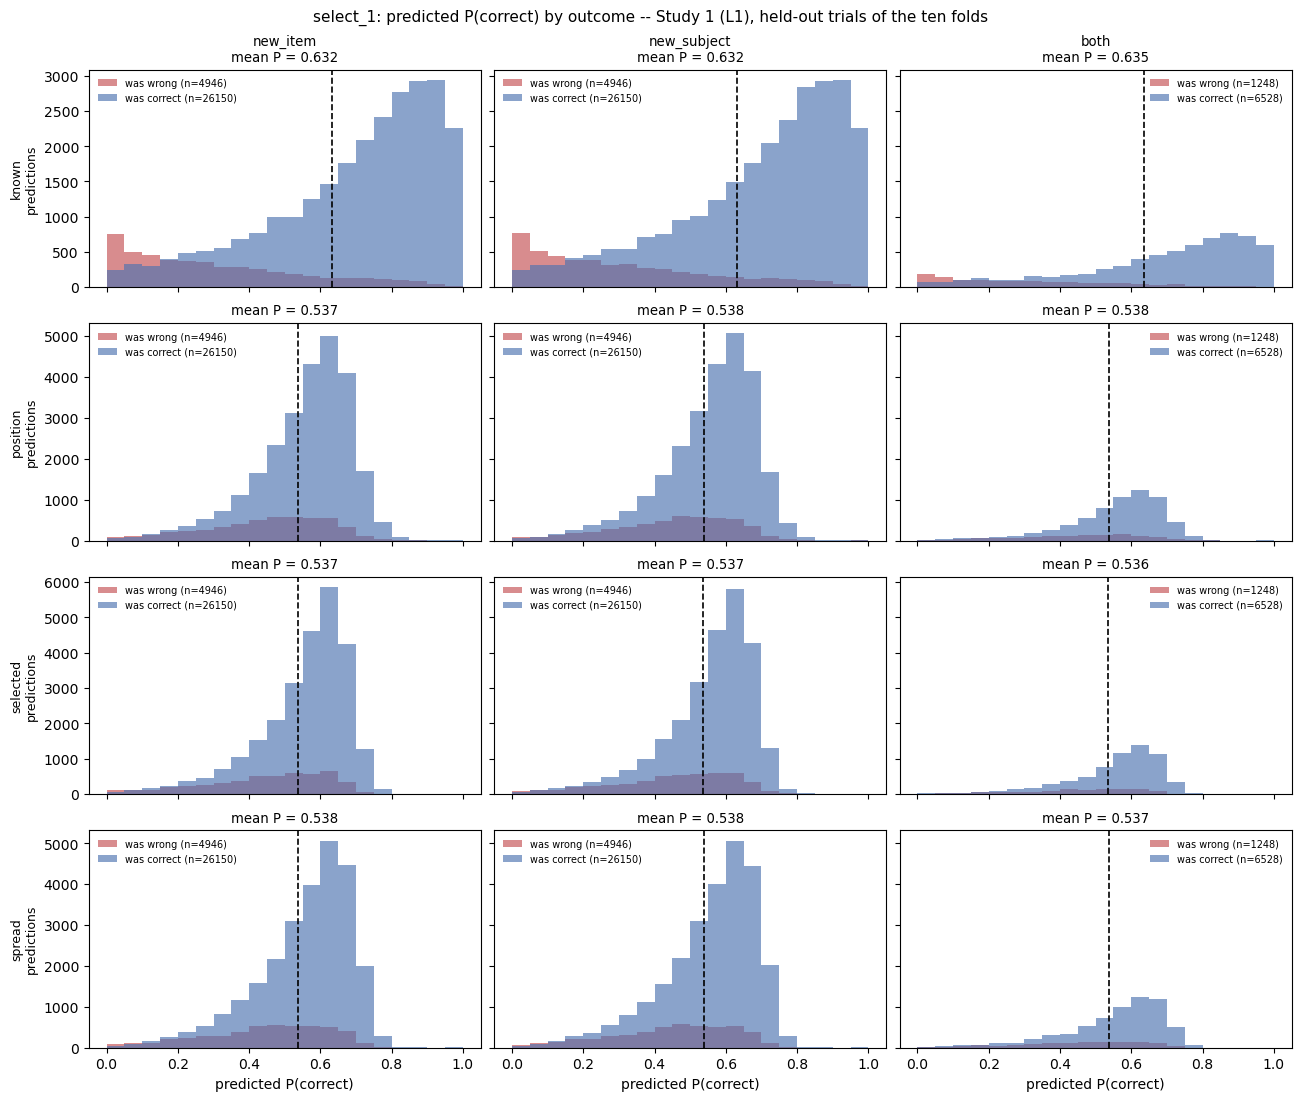

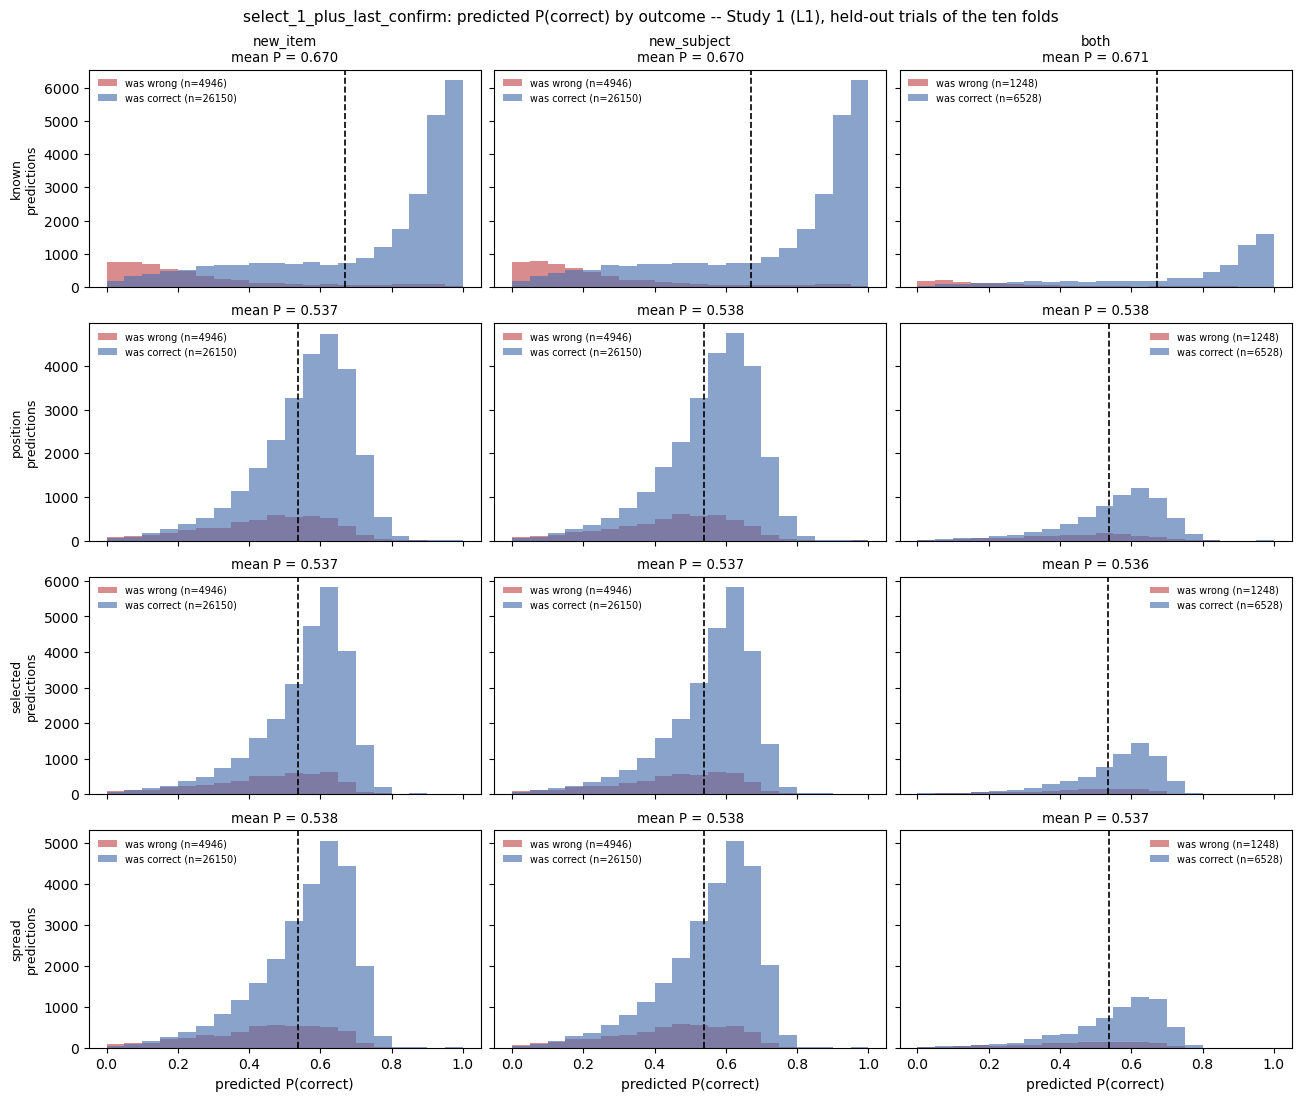

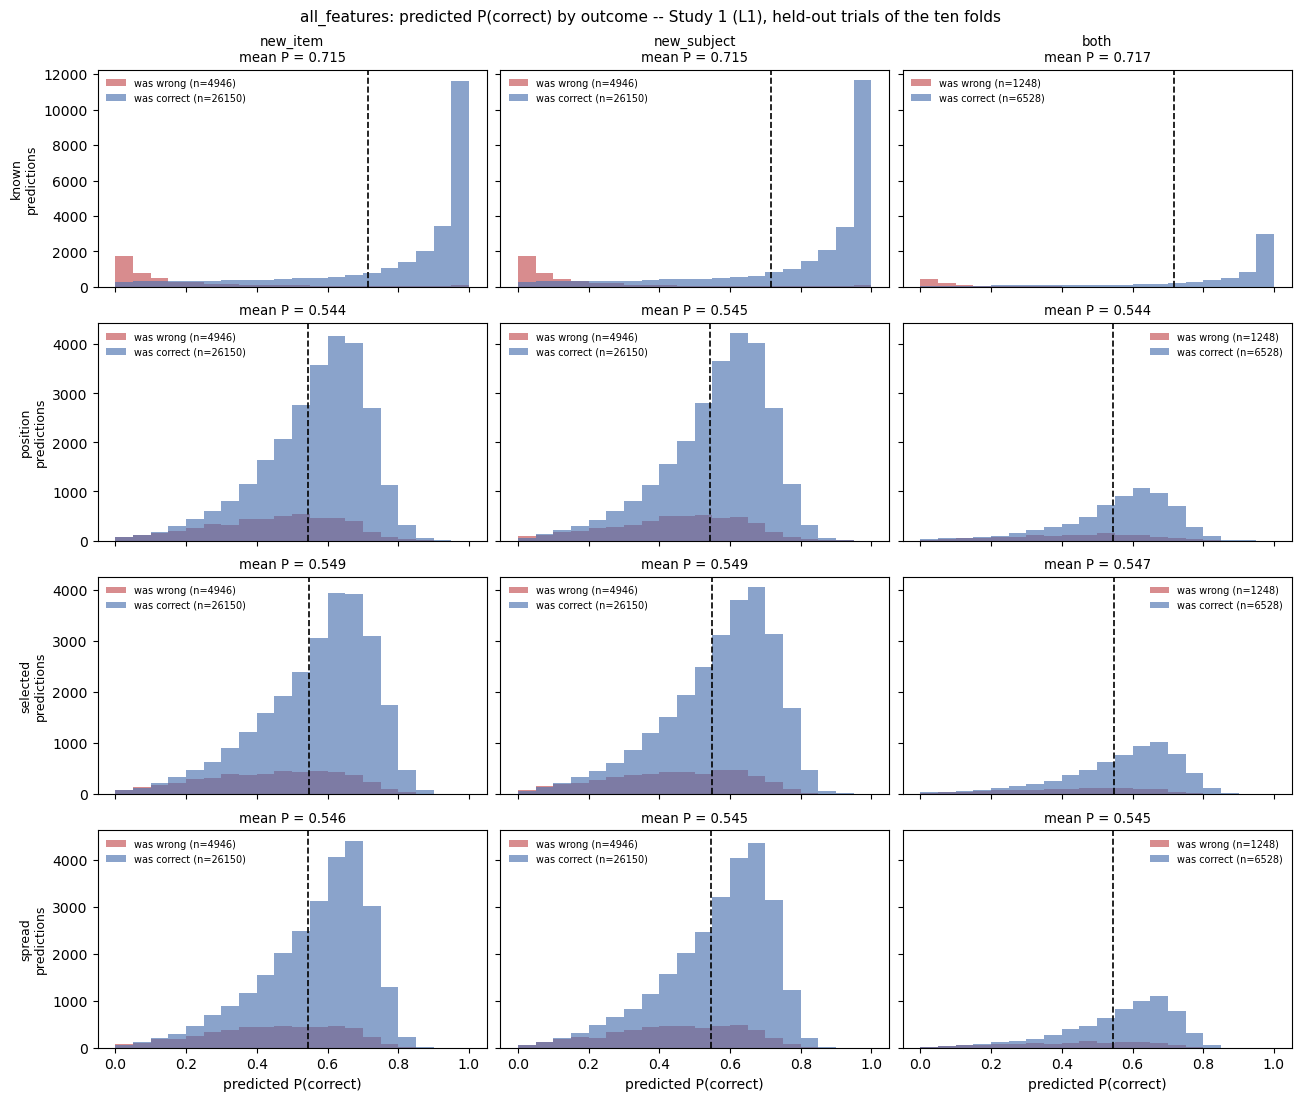

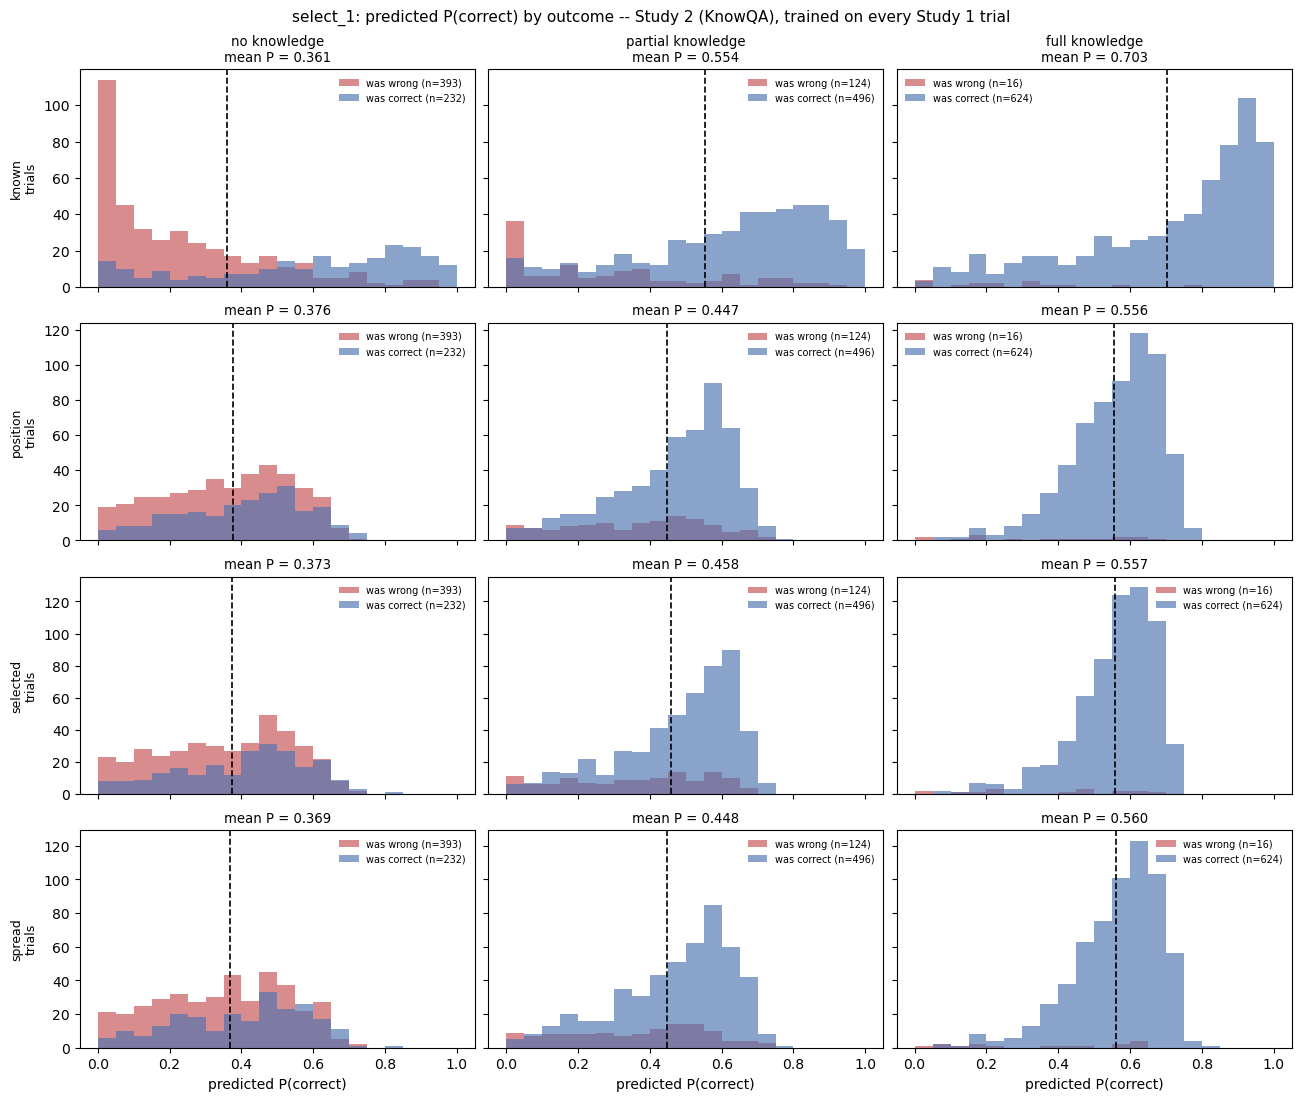

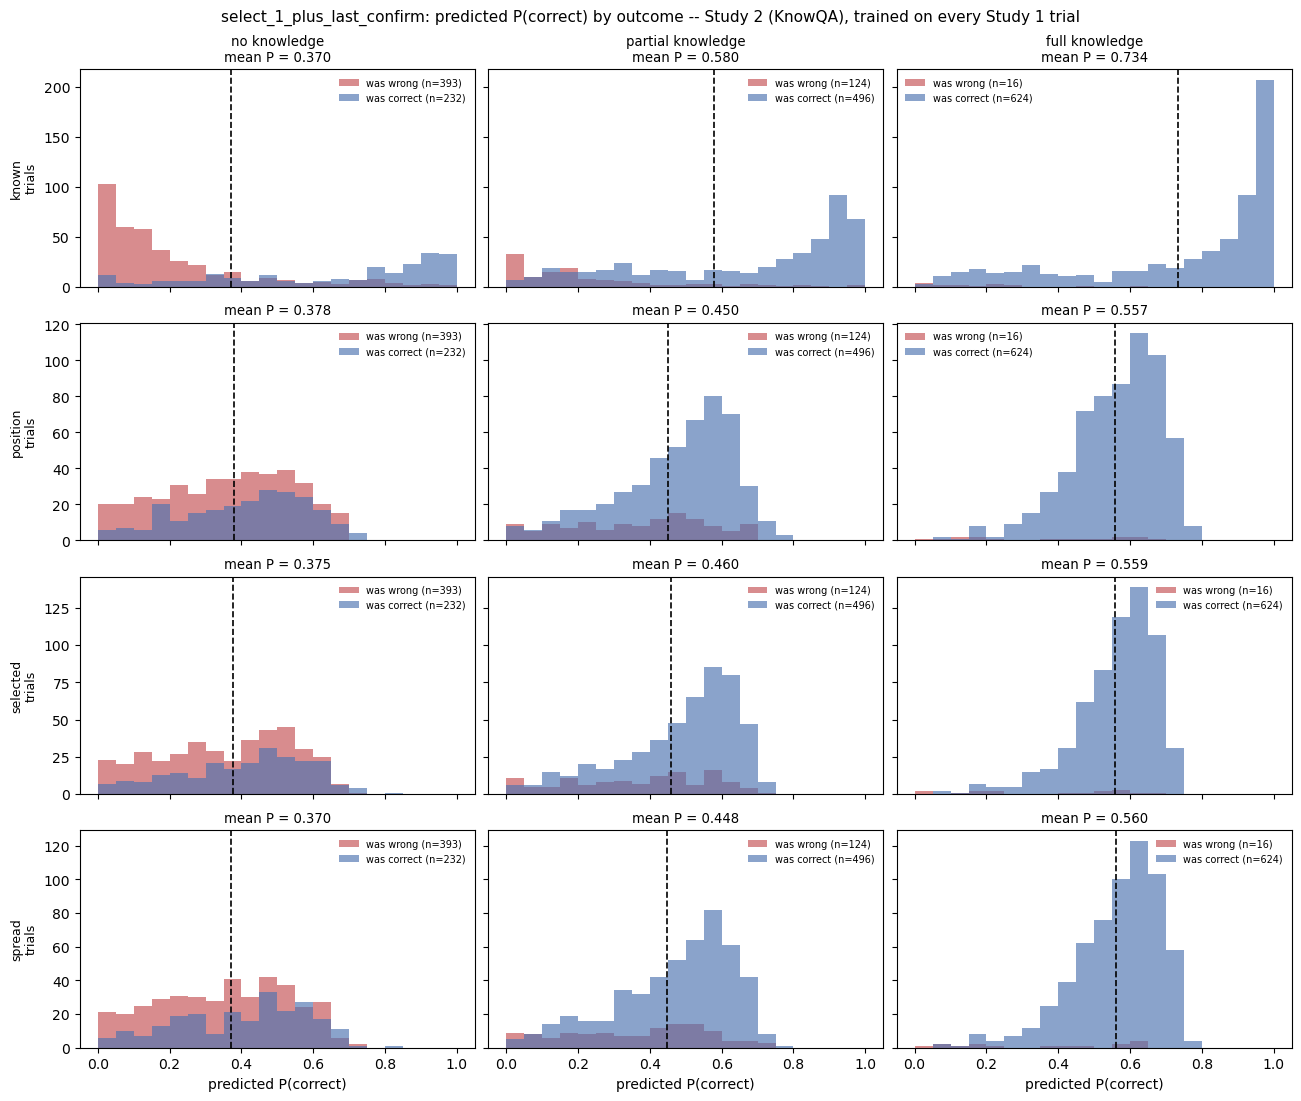

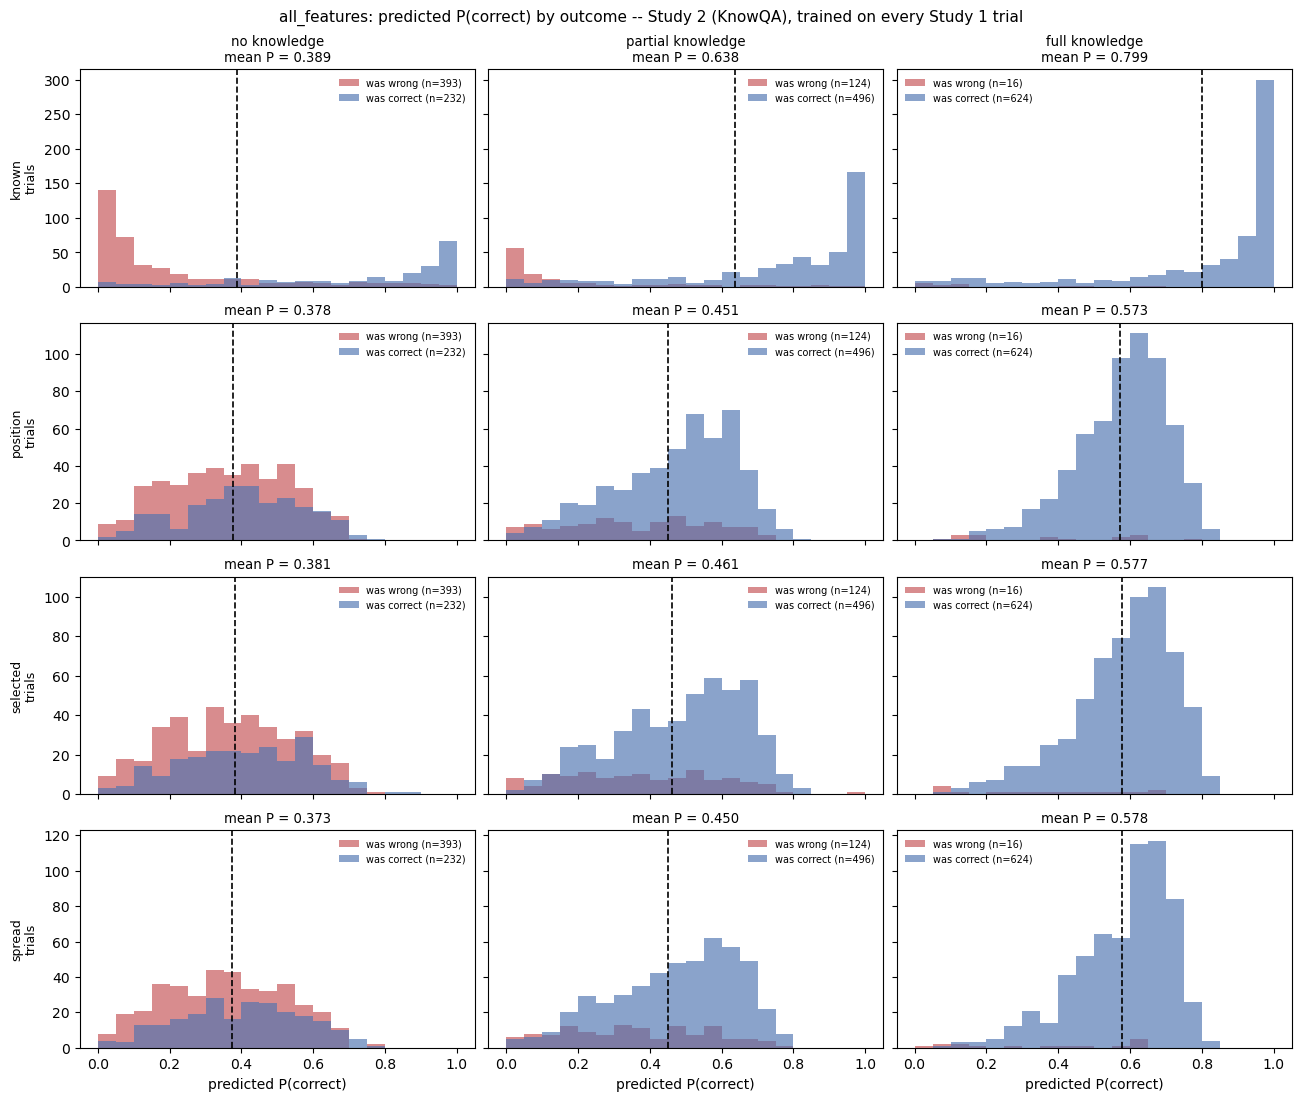

In [7]:
for ds in CONFUSION_TESTS:   # Study 1, then Study 2
    for paper_model in known:
        plot_probability_grid(preds, dataset=ds, paper_model=paper_model)
        plt.show()

The same predictions as box plots, drawn as in the Study 2 overview: for each test, a box for the
answers that were right (coloured) and one for those that were wrong (grey); whiskers at 1.5
times the interquartile range, no outliers drawn; the dotted line at 0.5. A panel per version.
The comparison the Study 2 figure is for is between the coloured boxes: if a version reads
knowledge rather than outcome, right answers under no knowledge (lucky guesses) should sit lower
than right answers under full knowledge.

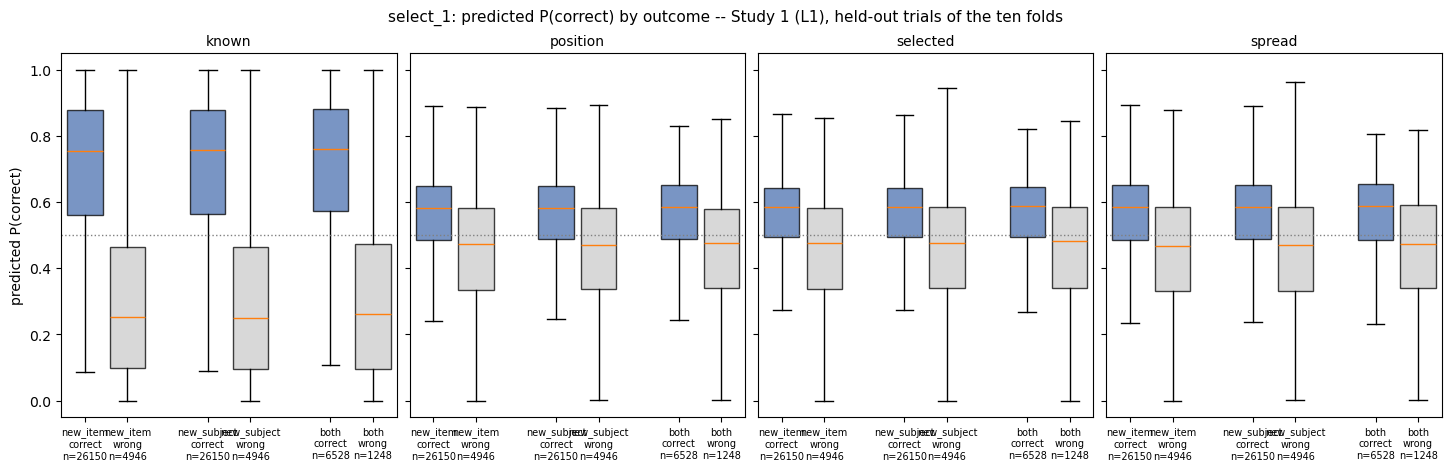

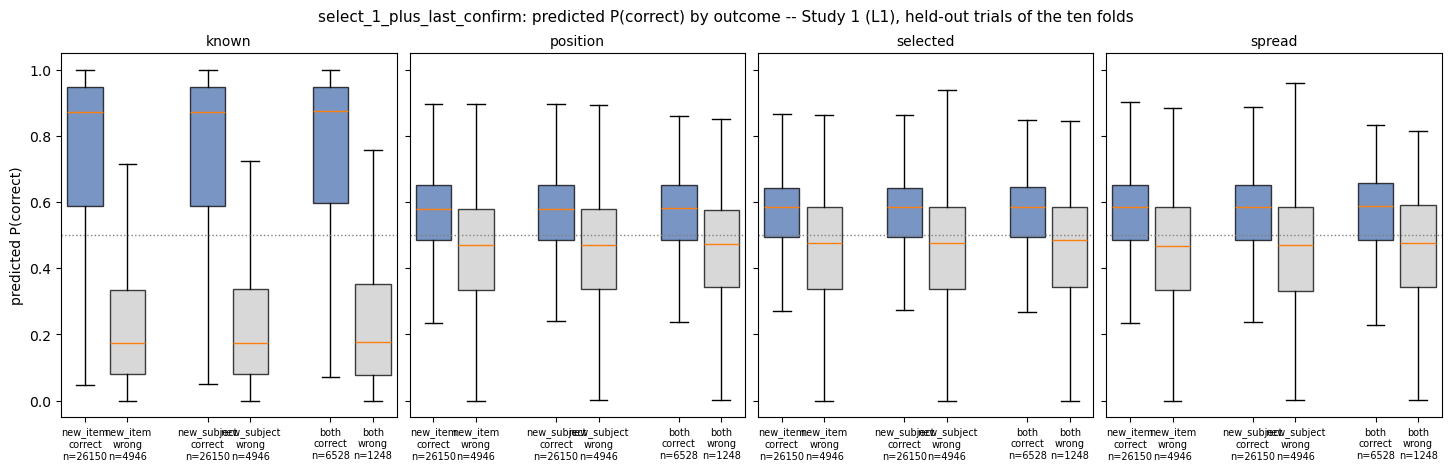

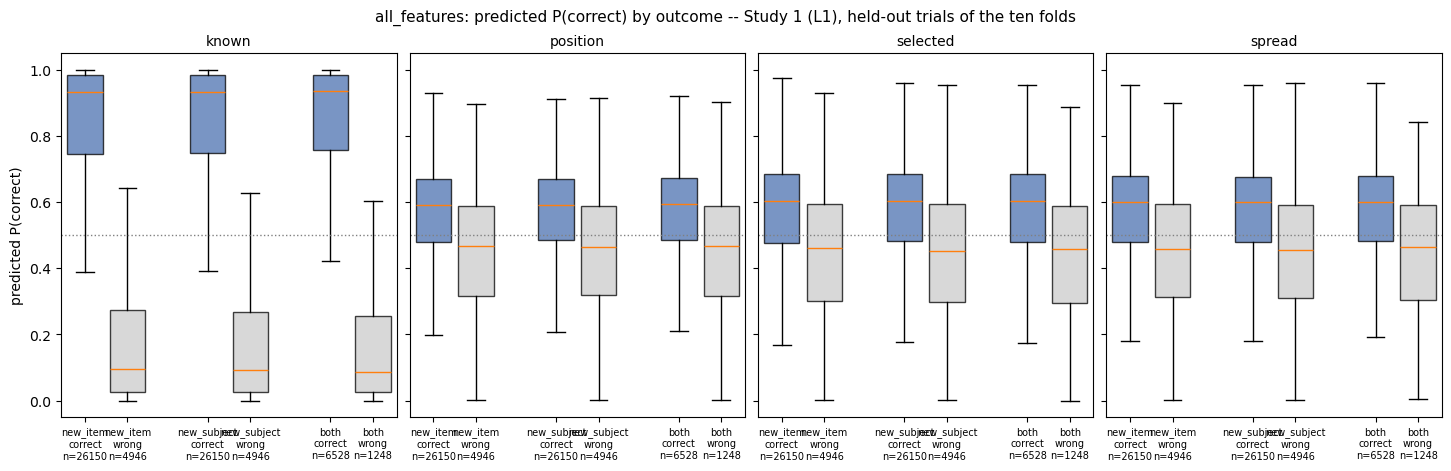

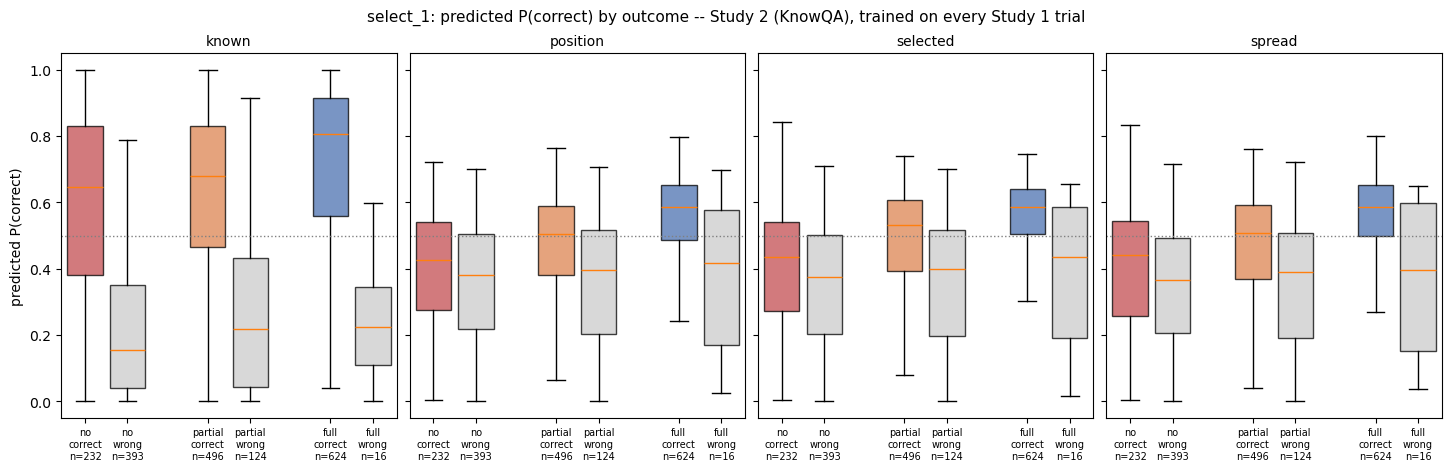

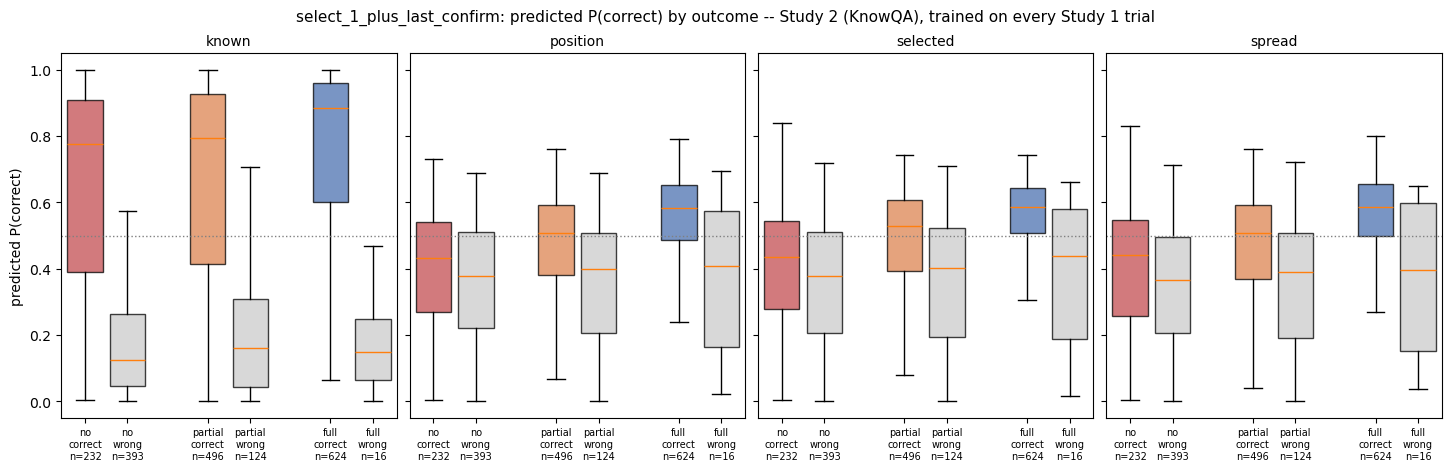

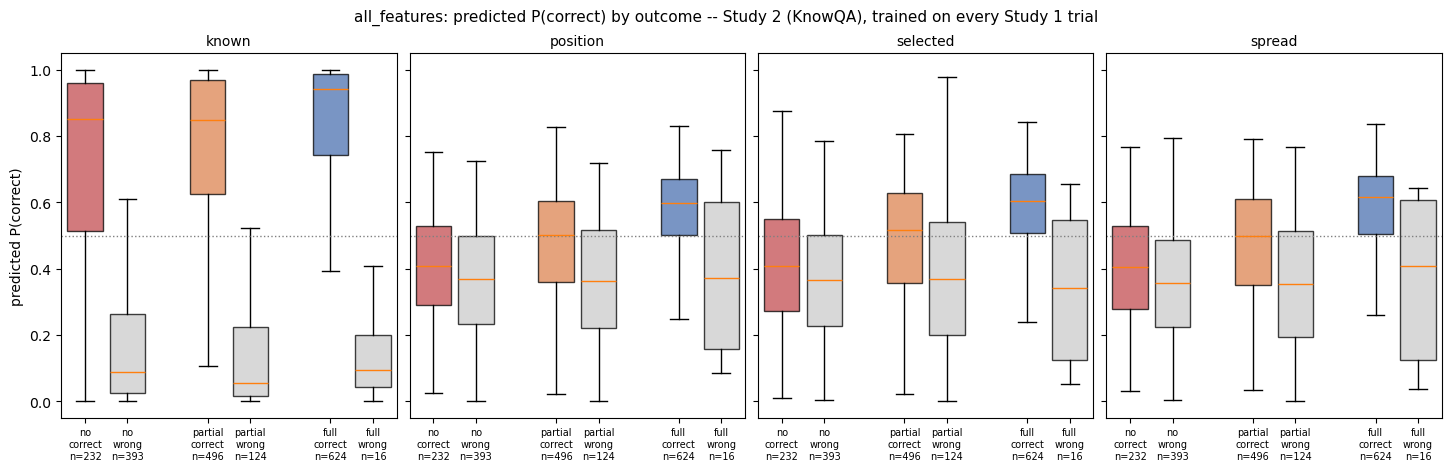

In [8]:
for ds in CONFUSION_TESTS:   # Study 1, then Study 2
    for paper_model in known:
        plot_probability_boxes(preds, dataset=ds, paper_model=paper_model)
        plt.show()

### Do right and wrong answers get different probabilities?
*`discrimination.discrimination_table`, `discrimination.plot_discrimination`*

The histograms above, as a test: for every version and test, the mean P(correct) on answers that
were right minus the mean on answers that were wrong, and the AUC (the chance that a random right
answer gets a higher P than a random wrong one; 0.5 is no discrimination). The 95% intervals and
the p-values come from resampling whole participants, as the paper's Study 2 test does, because a
person's answers are not independent; every version of a test is resampled with the same draws.

Two limits, the same as the paper's: the items are not resampled, though they recur across
people, and Study 2 has only 13 participants, so its intervals are likely too narrow. The p-value
cannot go below 1 / 2000, so "p < 0.0005" means none of the resamples crossed zero.

[cache] discrimination: read discrimination__54c848b8f42f.pkl


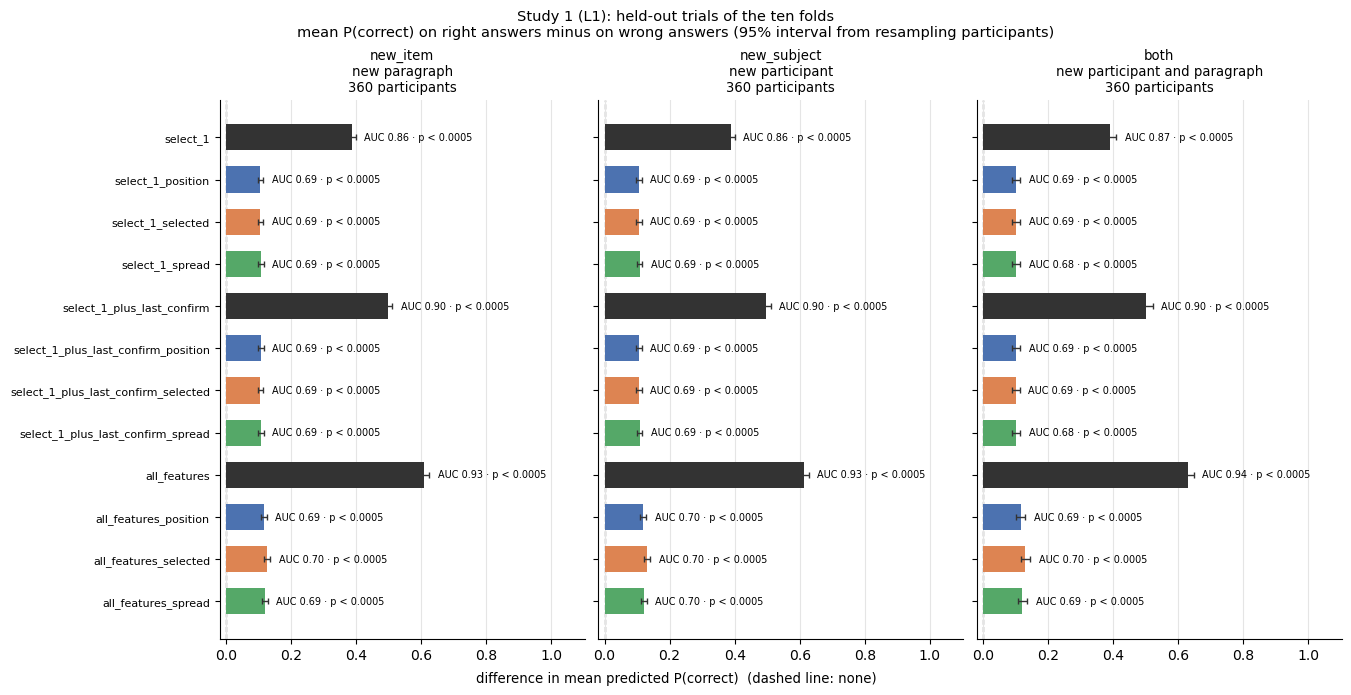

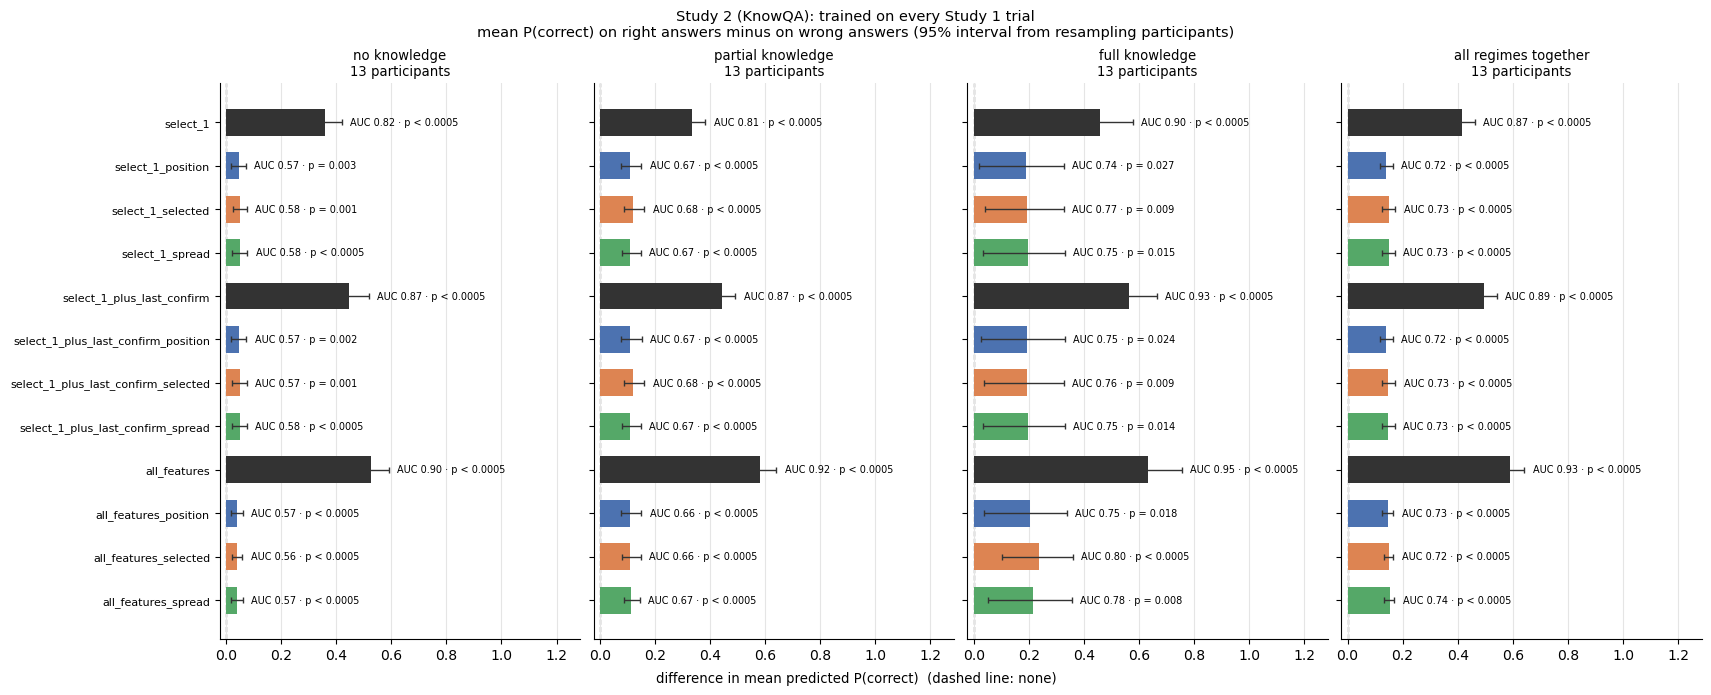

dataset                             knowqa                              \
test                                   all full knowledge no knowledge   
model                                                                    
select_1                             0.865          0.899        0.822   
select_1_position                    0.721          0.743        0.572   
select_1_selected                    0.734          0.765        0.575   
select_1_spread                      0.733          0.750        0.582   
select_1_plus_last_confirm           0.894          0.931        0.867   
select_1_plus_last_confirm_position  0.720          0.746        0.572   
select_1_plus_last_confirm_selected  0.733          0.764        0.575   
select_1_plus_last_confirm_spread    0.732          0.751        0.581   
all_features                         0.926          0.948        0.903   
all_features_position                0.729          0.750        0.567   
all_features_selected                0.724          0.805        0.563   
all_features_spread                  0.735          0.777        0.569   

dataset                                                   l1           \
test                                partial knowledge   both new_item   
model                                                                   
select_1                                        0.810  0.866    0.859   
select_1_position                               0.667  0.687    0.689   
select_1_selected                               0.681  0.689    0.691   
select_1_spread                                 0.669  0.683    0.691   
select_1_plus_last_confirm                      0.867  0.904    0.900   
select_1_plus_last_confirm_position             0.670  0.686    0.689   
select_1_plus_last_confirm_selected             0.680  0.688    0.691   
select_1_plus_last_confirm_spread               0.669  0.683    0.690   
all_features                                    0.923  0.943    0.932   
all_features_position                           0.659  0.690    0.693   
all_features_selected                           0.658  0.702    0.696   
all_features_spread                             0.669  0.695    0.695   

dataset                                          
test                                new_subject  
model                                            
select_1                                  0.859  
select_1_position                         0.690  
select_1_selected                         0.692  
select_1_spread                           0.692  
select_1_plus_last_confirm                0.900  
select_1_plus_last_confirm_position       0.690  
select_1_plus_last_confirm_selected       0.691  
select_1_plus_last_confirm_spread         0.691  
all_features                              0.933  
all_features_position                     0.697  
all_features_selected                     0.702  
all_features_spread                       0.698

In [9]:
disc = discrimination_table(preds)
for ds in CONFUSION_TESTS:
    plot_discrimination(disc, dataset=ds, models=model_order(known))
    plt.show()
display(disc.pivot_table(index="model", columns=["dataset", "test"], values="auc", observed=True)
        .loc[model_order(known)].round(3))

### Against the participants' own confidence (Study 2)
*`discrimination.plot_confidence_roc`, `discrimination.confidence_comparison`*

The Study 2 overview's comparison of the model with the confidence rating, for every version:
ROC curves per regime, a curve per version beside the self-report curve, and the paper's test of
the model's AUC against the rating's (model minus rating, with intervals from resampling
participants; every version resampled with the same draws). As there, P(correct) is cut into five
equal-width bins so that it has as many levels as the five-point rating. The answer-hidden
versions' P covers a narrower range, so the bins cost them 0.01-0.03 of AUC, about what they cost
the paper's model; the table below the figures also gives the comparison on the raw probability.
The bootstraps take about two minutes the first time.

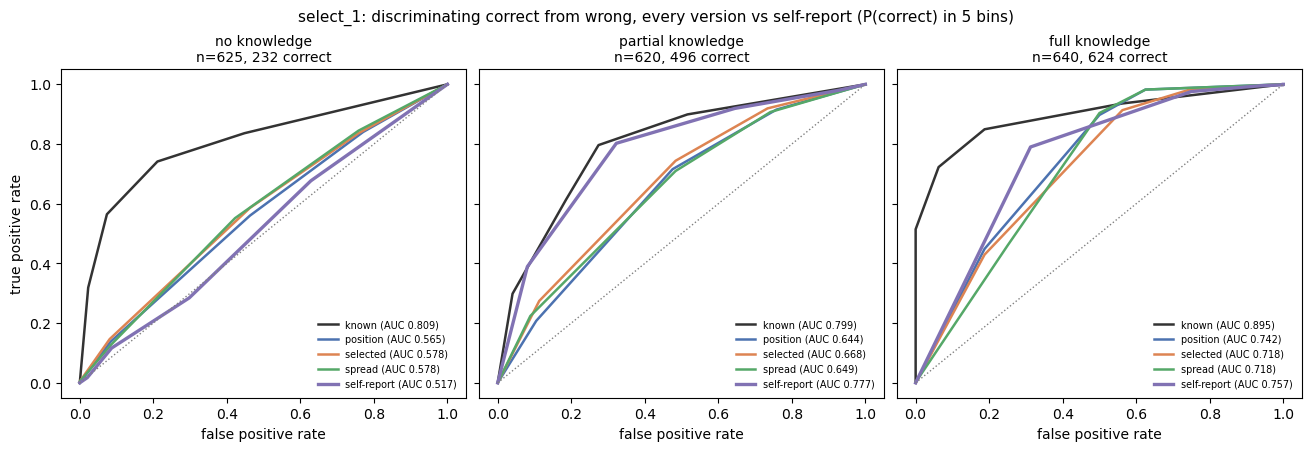

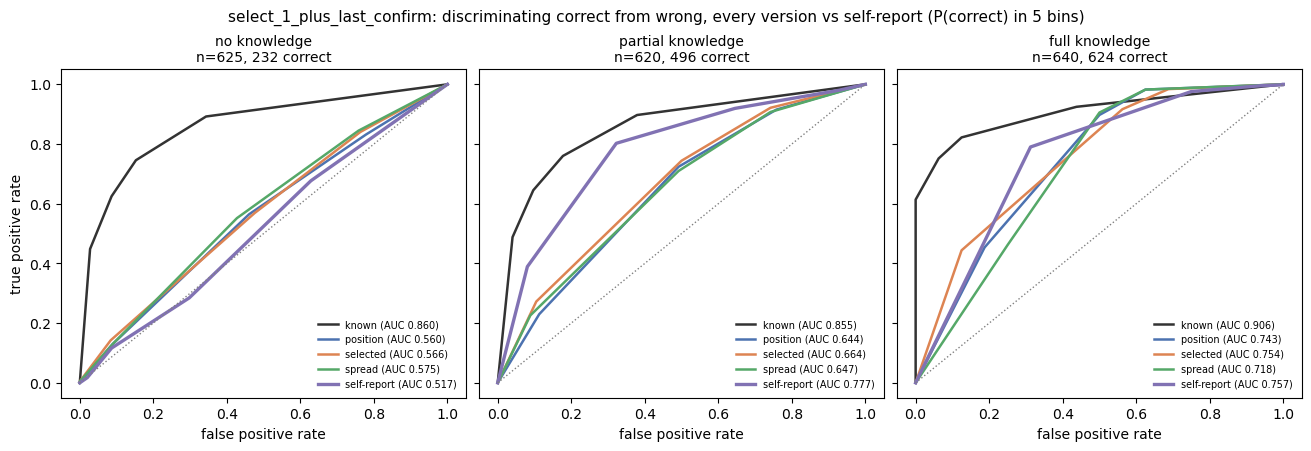

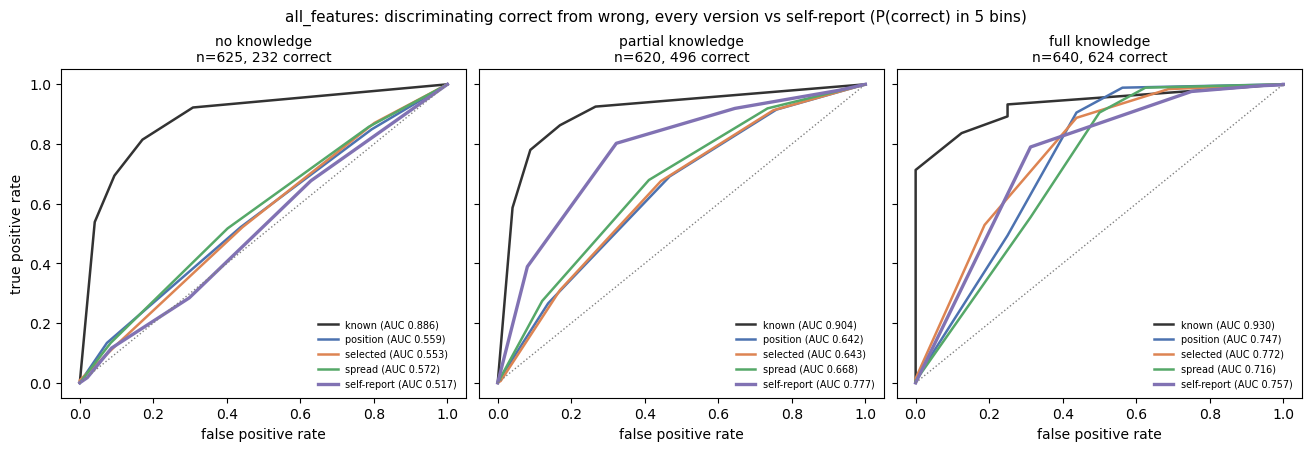

P(correct) in 5 bins
[cache] confidence_comparison: read confidence_comparison__fa9b117d38ca.pkl


,model,regime,auc_model,auc_confidence,diff,diff_ci_low,diff_ci_high,p
0,select_1,no knowledge,0.809,0.517,0.292,0.225,0.356,0.000
1,select_1,partial knowledge,0.799,0.777,0.022,-0.040,0.086,0.468
2,select_1,full knowledge,0.895,0.757,0.138,0.058,0.236,0.001
3,select_1_position,no knowledge,0.565,0.517,0.047,-0.034,0.121,0.308
4,select_1_position,partial knowledge,0.644,0.777,-0.133,-0.192,-0.069,0.000
5,select_1_position,full knowledge,0.742,0.757,-0.015,-0.112,0.079,0.769
6,select_1_selected,no knowledge,0.578,0.517,0.060,-0.012,0.126,0.114
7,select_1_selected,partial knowledge,0.668,0.777,-0.110,-0.156,-0.060,0.000
8,select_1_selected,full knowledge,0.718,0.757,-0.039,-0.123,0.042,0.374
9,select_1_spread,no knowledge,0.578,0.517,0.060,-0.014,0.129,0.125


raw P(correct)
[cache] confidence_comparison: read confidence_comparison__10022708784c.pkl


,model,regime,auc_model,auc_confidence,diff,diff_ci_low,diff_ci_high,p
0,select_1,no knowledge,0.822,0.517,0.305,0.237,0.369,0.000
1,select_1,partial knowledge,0.810,0.777,0.033,-0.027,0.097,0.259
2,select_1,full knowledge,0.899,0.757,0.142,0.077,0.223,0.000
3,select_1_position,no knowledge,0.572,0.517,0.055,-0.021,0.124,0.183
4,select_1_position,partial knowledge,0.667,0.777,-0.110,-0.164,-0.049,0.001
5,select_1_position,full knowledge,0.743,0.757,-0.013,-0.119,0.104,0.873
6,select_1_selected,no knowledge,0.575,0.517,0.058,-0.013,0.121,0.109
7,select_1_selected,partial knowledge,0.681,0.777,-0.097,-0.143,-0.045,0.001
8,select_1_selected,full knowledge,0.765,0.757,0.008,-0.088,0.102,0.801
9,select_1_spread,no knowledge,0.582,0.517,0.065,-0.008,0.132,0.087


In [10]:
for paper_model in known:
    plot_confidence_roc(preds, tables["knowqa"], paper_model=paper_model)
    plt.show()

cols = ["model", "regime", "auc_model", "auc_confidence", "diff", "diff_ci_low", "diff_ci_high", "p"]
for bins in (5, None):
    print("P(correct) in 5 bins" if bins else "raw P(correct)")
    display(confidence_comparison(preds, tables["knowqa"], model_order(known), model_bins=bins)[cols].round(3))

## 4. What the answer-free models lean on
*`run.collect_answer_hidden_coefficients`*

The three versions of the paper's twelve-feature model, each from one fit on every Study 1 trial,
as the paper's coefficients are made: features standardised, so each coefficient is the change in
log-odds of a correct answer per standard deviation, with 95% intervals from a bootstrap that
resamples whole participants. About a minute per model. (`run.main` saves the same for the
ten-feature model too.)

A *position* coefficient is about that place on screen, whatever answer happened to be there. A
*selected* coefficient is about the chosen answer against the others, the paper's construction
with the choice in place of the key. A *spread* coefficient is about how unevenly the answers
were read.

[cache] coefficients: read coefficients__c879b7c621ea.pkl
[cache] coefficients: read coefficients__291e5aac1e2b.pkl
[cache] coefficients: read coefficients__9e7c12ba3df4.pkl


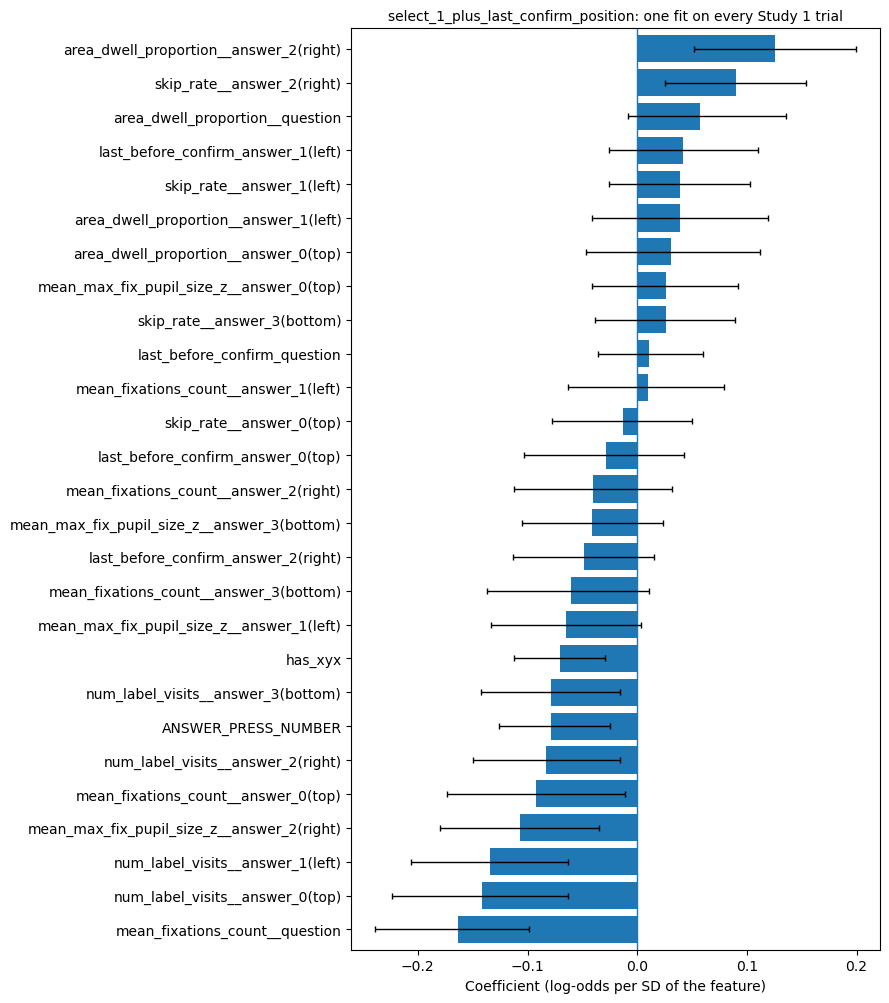

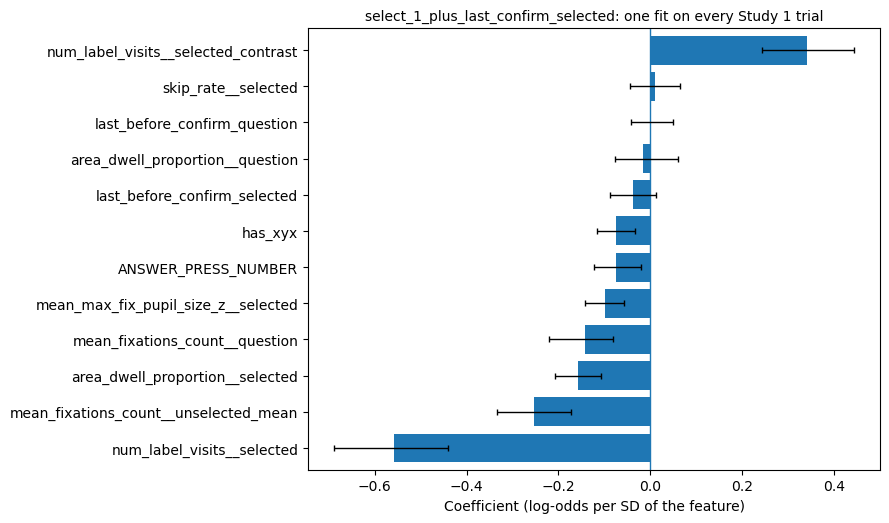

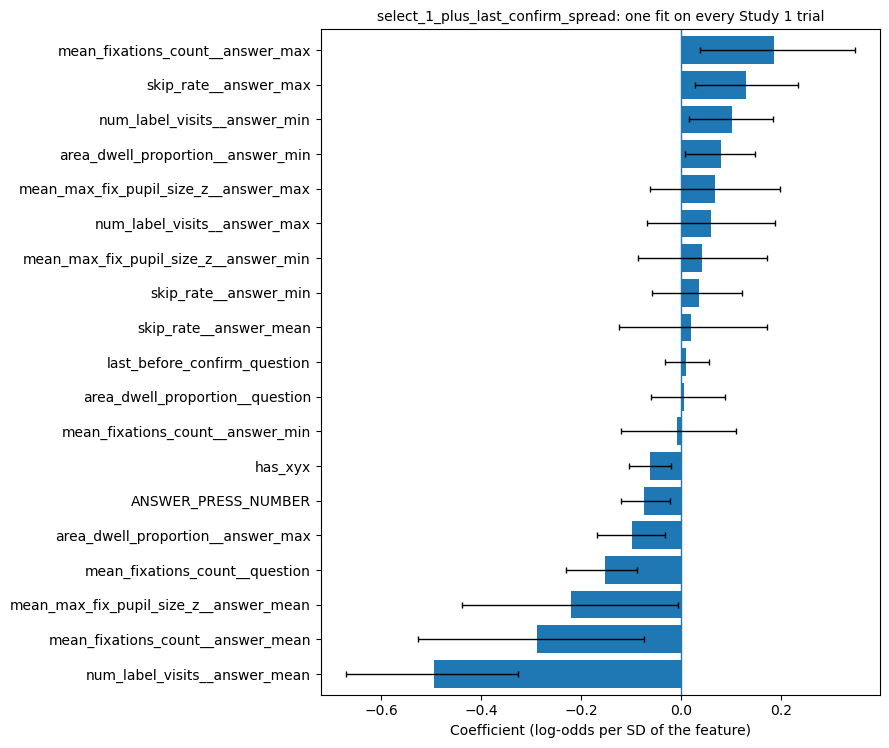

In [11]:
coefs = collect_answer_hidden_coefficients(
    l1_hidden, answer_free_feature_sets({"select_1_plus_last_confirm": known["select_1_plus_last_confirm"]}),
)
for name, coef in coefs.items():
    plot_answer_hidden_coefficients(coef, model=name)
    plt.show()

## 5. Deliberation features, selected version
*`deliberation.combination_sets`, `deliberation.plot_search_heatmap`*

The *selected* version of the twelve-feature model (the **base**) describes the chosen answer
against the others. Here groups of features that describe how much the participant deliberated
are added to it, in every combination, and also tried on their own without the base:

* **back_and_forth** -- the longest stretch going back and forth between two answers, and whether
  the scan ended x-y-x or x-y-x-y;
* **visits** -- how many areas were entered in all, and how many times the chosen answer, the
  others and the question were;
* **choice** -- how many times an answer was selected, and whether the last looks before the
  selecting and confirming presses were at the chosen answer or the question;
* **time** -- time on the whole answer screen, time on the chosen answer and on the others, and
  the span from the first to the last look at them, all per word;
* **question** -- the share of time on the question, fixations per word on it, and time on it.

Every set is scored by the paper's comparison. A low score under **no knowledge** is not a failure
here: those right answers were guesses, and a model that reads how sure someone was should not
call them right. Takes about two and a half minutes.

,columns
back_and_forth,"longest_alt_answer_run, has_xyx, has_xyxy"
visits,"seq_len, num_label_visits__selected, num_label..."
choice,"ANSWER_PRESS_NUMBER, last_before_select_select..."
time,"total_answering_RT_normalized, RT_normalized_s..."
question,"area_dwell_proportion__question, mean_fixation..."


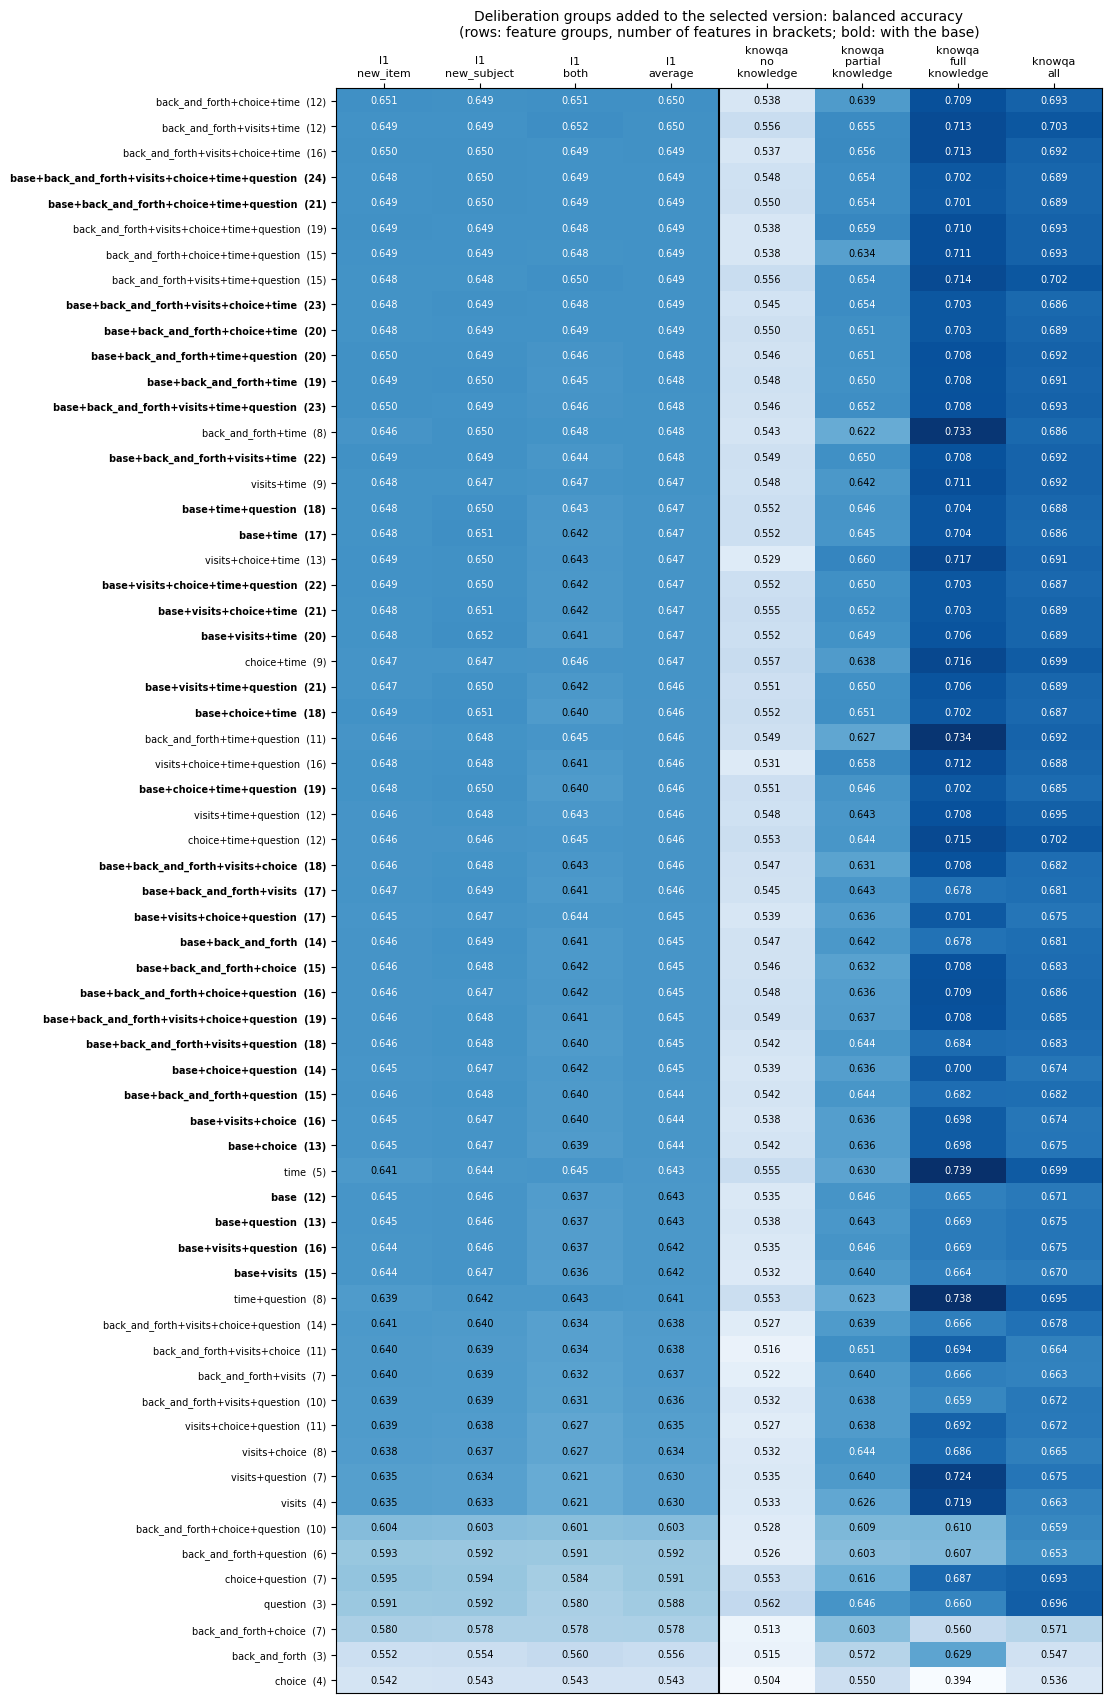

In [12]:
display(pd.Series({g: ", ".join(cols) for g, cols in DELIBERATION_GROUPS.items()}, name="columns").to_frame())

search = run_deliberation_search(tables, combination_sets(base_cols()), verbose=False)
fig, search_table = plot_search_heatmap(search["scores"])
plt.show()

A few of them as the comparison's bars, with Study 1's interval across folds: the base, the time
group alone and added to the base, the two best Study 1 sets of twelve features, and everything.
The folds share most of their training data, so these intervals are narrower than the real
uncertainty, and differences of a few thousandths between sets are not to be read as real.

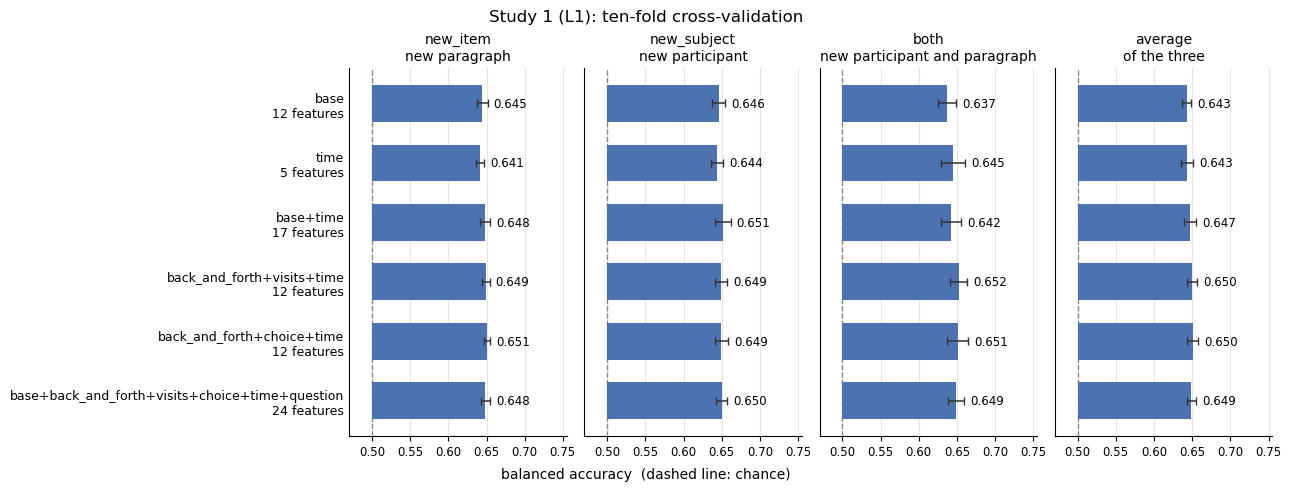

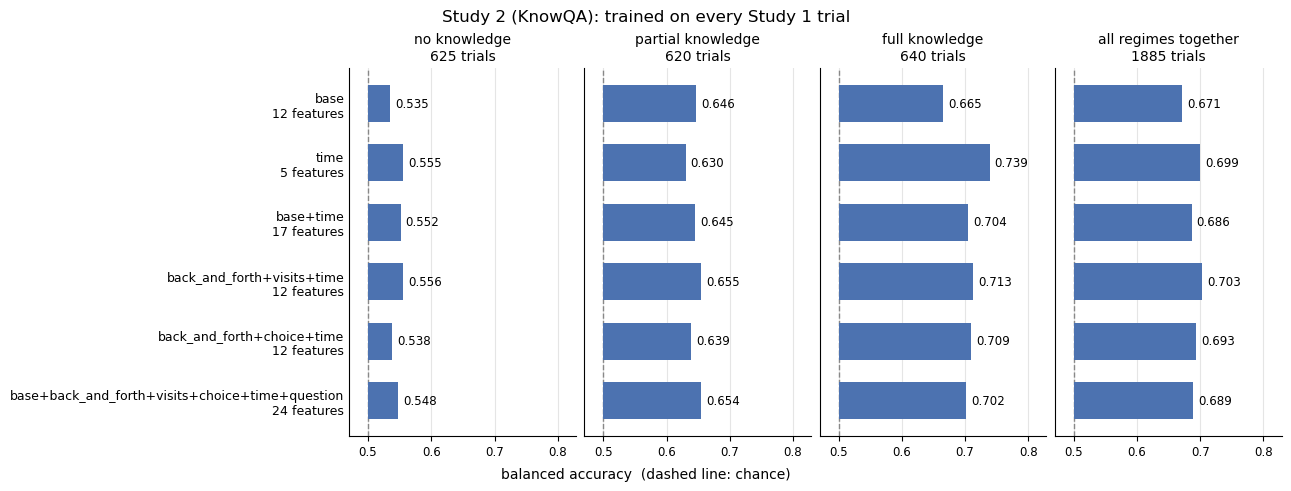

In [13]:
for ds in TESTS:
    plot_answer_hidden_comparison(search, dataset=ds, models=SHORT_LIST, models_shown="deliberation")
    plt.show()

## 6. Features built around the selected answer
*`selected_features.build_selected_features`, `deliberation.selected_feature_sets`*

Six new features, each about the chosen answer and none needing the answer key
(`selected_features.py` has the exact definitions):

* **selected_sequence**, from the order in which the areas were visited:
  * `selected_switches` -- moves straight between the chosen answer and another answer;
  * `selected_alt_run` -- the longest back-and-forth between the chosen answer and one other
    answer, the sequence statistic `longest_alt_answer_run` limited to the chosen answer;
  * `others_before_selected`, `others_after_selected` -- how many other answers were visited
    before the chosen one was first reached, and after.
* **selected_timing**, from the press times and the fixation report:
  * `first_look_to_select_ms` -- from the first look at the chosen answer to selecting it;
  * `select_to_confirm_ms` -- from selecting it to confirming.

Where the chosen answer was never looked at, the features that need a first look have no value,
and where no selection press was recorded, neither time has one: 20 and 24 trials on Study 1,
1 and 0 on Study 2 (counted below). The model fills them with 0 and warns, as it does for every
missing value. They are part of the saved answer-hidden table (`table.load_hidden_table`).

Each of the anchors below is scored alone, with each new group, and with both: nothing, the base,
the time group alone and with the base, the best twelve-feature set of section 5, and everything
there.

,selected_switches,selected_alt_run,others_before_selected,others_after_selected,first_look_to_select_ms,select_to_confirm_ms
count,19436.0,19436.0,19416.0,19416.0,19406.0,19412.0
mean,3.2,2.6,1.5,2.0,3761.8,1368.3
std,1.9,0.9,1.1,1.1,4023.1,1754.0
min,0.0,0.0,0.0,0.0,-2353.0,68.0
25%,2.0,2.0,0.0,1.0,1257.2,432.0
50%,3.0,2.0,1.0,2.0,2414.5,716.0
75%,4.0,3.0,2.0,3.0,4905.2,1566.2
max,25.0,12.0,3.0,3.0,116149.0,29496.0


missing, per feature: {'selected_switches': 0, 'selected_alt_run': 0, 'others_before_selected': 20, 'others_after_selected': 20, 'first_look_to_select_ms': 30, 'select_to_confirm_ms': 24}


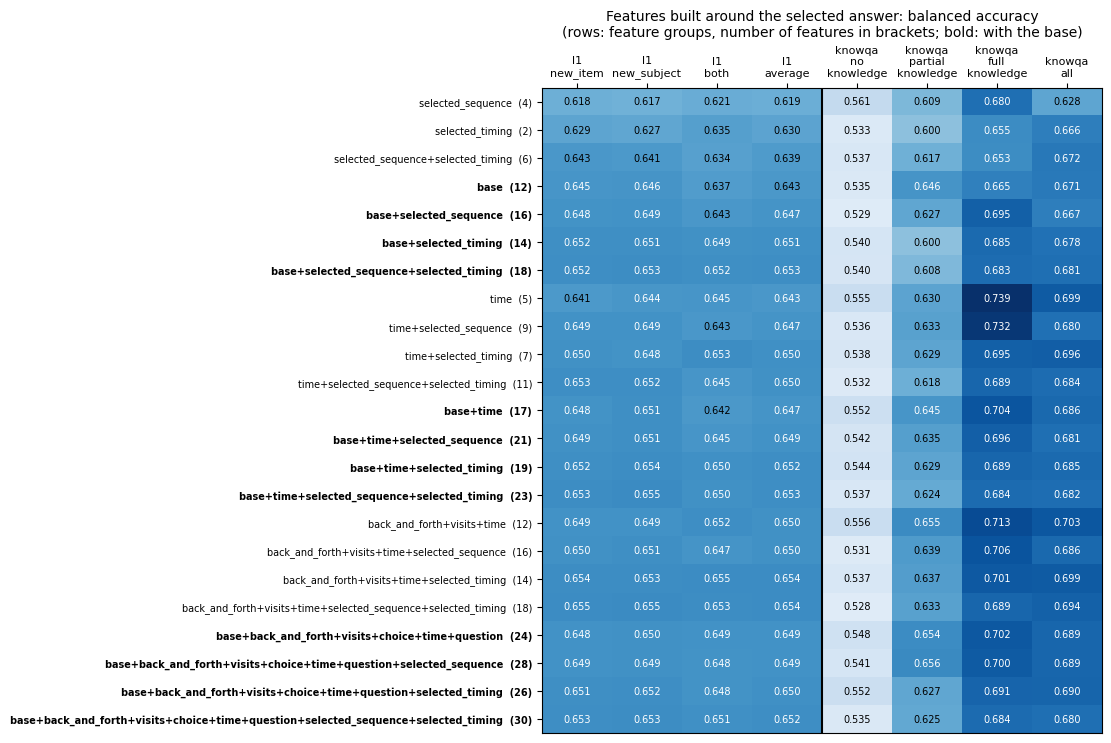

In [14]:
display(tables["l1_hidden"][SELECTED_FEATURES].describe().round(1))
print("missing, per feature:", tables["l1_hidden"][SELECTED_FEATURES].isna().sum().to_dict())

selected_sets = selected_feature_sets(base_cols())
selected_search = run_deliberation_search(tables, selected_sets, verbose=False)
fig, selected_table = plot_search_heatmap(selected_search["scores"], search="selected", order=list(selected_sets))
plt.show()

## 7. Matching: did the chosen answer stand out?
*`matching.add_matching_features`, `matching.matching_summary`, `matching.matching_feature_sets`*

The correctness-associations analysis asks whether the answer chosen is the one the eyes
favoured. Here that becomes features, one 0/1 column per measure and way:

* **matching_polarity** -- the chosen answer has the highest value of the four (the lowest for
  skip rate and the smallest pupil size);
* **matching_relative** -- the chosen answer is the one furthest from the four answers' mean,
  in either direction.

Ten measures each, the per-area measures of the paper's model. Neither needs the answer key.

**A tie counts as matching** when the chosen answer is among the tied ones, as in the
correctness-associations code. Breaking it by letter would leak the answer key, since
`answer_A` is always the correct answer. Ties are common on the counted measures: `num_label_visits` ties at its top on 45% of Study 1
trials, `skip_rate` at its bottom on 18%.

The table: for each feature, accuracy on the trials where it matched minus accuracy on the
rest. Study 2's pooled column mixes the regimes, which differ in both accuracy and how often
the chosen answer stands out, so the regimes are the columns to read there.

In [15]:
matching_tables = with_matching(tables)
display(matching_summary(matching_tables)["difference"].round(3))

dataset                                                                  l1  \
test                                                                    all   
group             feature                                                     
matching_polarity mean_dwell_time__matching_polarity                  0.020   
                  mean_fixations_count__matching_polarity             0.016   
                  mean_first_fixation_duration__matching_polarity     0.018   
                  skip_rate__matching_polarity                        0.011   
                  area_dwell_proportion__matching_polarity           -0.002   
                  mean_avg_fix_pupil_size_z__matching_polarity        0.007   
                  mean_max_fix_pupil_size_z__matching_polarity       -0.002   
                  mean_min_fix_pupil_size_z__matching_polarity        0.016   
                  first_encounter_avg_pupil_size_z__matching_pola... -0.012   
                  num_label_visits__matching_polarity                 0.049   
matching_relative mean_dwell_time__matching_relative                  0.017   
                  mean_fixations_count__matching_relative             0.012   
                  mean_first_fixation_duration__matching_relative     0.015   
                  skip_rate__matching_relative                        0.013   
                  area_dwell_proportion__matching_relative            0.002   
                  mean_avg_fix_pupil_size_z__matching_relative        0.018   
                  mean_max_fix_pupil_size_z__matching_relative        0.010   
                  mean_min_fix_pupil_size_z__matching_relative        0.019   
                  first_encounter_avg_pupil_size_z__matching_rela...  0.004   
                  num_label_visits__matching_relative                 0.070   

dataset                                                                    knowqa  \
test                                                                 no knowledge   
group             feature                                                           
matching_polarity mean_dwell_time__matching_polarity                        0.048   
                  mean_fixations_count__matching_polarity                   0.024   
                  mean_first_fixation_duration__matching_polarity          -0.015   
                  skip_rate__matching_polarity                              0.018   
                  area_dwell_proportion__matching_polarity                  0.032   
                  mean_avg_fix_pupil_size_z__matching_polarity              0.045   
                  mean_max_fix_pupil_size_z__matching_polarity              0.012   
                  mean_min_fix_pupil_size_z__matching_polarity              0.022   
                  first_encounter_avg_pupil_size_z__matching_pola...        0.026   
                  num_label_visits__matching_polarity                      -0.025   
matching_relative mean_dwell_time__matching_relative                        0.052   
                  mean_fixations_count__matching_relative                   0.101   
                  mean_first_fixation_duration__matching_relative          -0.027   
                  skip_rate__matching_relative                              0.007   
                  area_dwell_proportion__matching_relative                  0.019   
                  mean_avg_fix_pupil_size_z__matching_relative              0.077   
                  mean_max_fix_pupil_size_z__matching_relative              0.064   
                  mean_min_fix_pupil_size_z__matching_relative              0.052   
                  first_encounter_avg_pupil_size_z__matching_rela...        0.011   
                  num_label_visits__matching_relative                       0.040   

dataset                                                                                 \
test                                                                 partial knowledge   
group             feature                     

The two groups alone, and added to the base, to the chosen set (back_and_forth + visits + time)
and to the two together, each scored by the paper's comparison as in section 5.

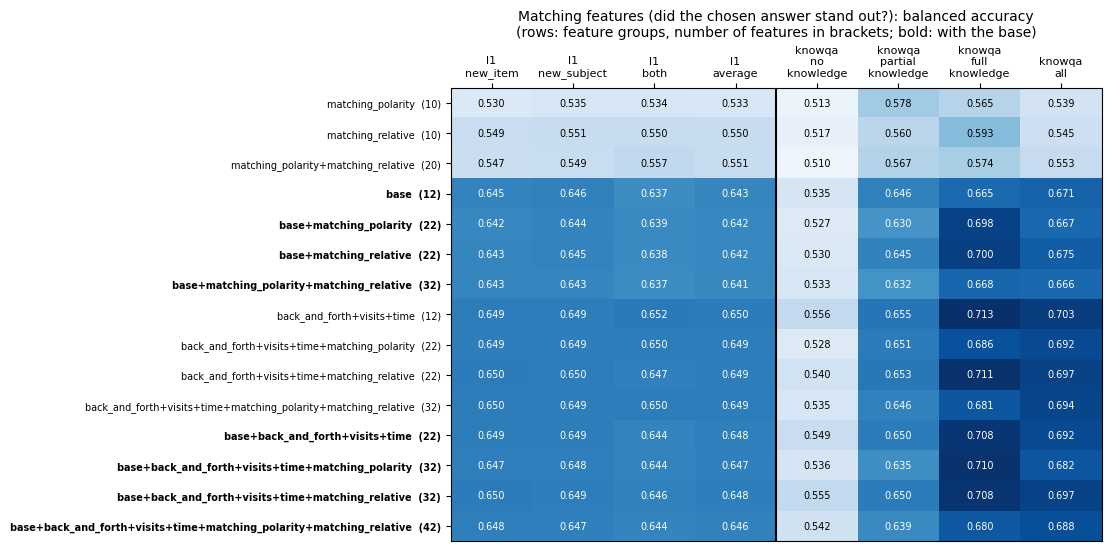

In [16]:
matching_sets = matching_feature_sets()
matching_search = run_deliberation_search(matching_tables, matching_sets, verbose=False)
fig, matching_table = plot_search_heatmap(matching_search["scores"], search="matching", order=list(matching_sets))
plt.show()

## 8. What needs an eye tracker
*`tracker.tracker_feature_sets`*

Some features need no eye tracker: the answering time and that per word on screen, the number of
selection presses and the time from selecting to confirming all come from the press log and the
text (`NO_TRACKER_COLS`). Of those that need one, some measure **how long** the eyes stayed
(reading times, dwell time and share, first-fixation duration, first look to selecting) and the
rest **where and in what order** they went (visits, back-and-forth, fixation counts, skip rate,
pupil, the last look).

The sets: the no-tracker features alone (and the answering time per word alone); the chosen set,
then without its no-tracker feature, then without the gaze times as well; the same two cuts of a
wider eye-tracker set (the base, back-and-forth, visits and the chosen answer's order features);
and that wider no-time set with the no-tracker features added back.

In [ ]:
tracker_sets = tracker_feature_sets()
display(pd.Series({k: len(v) for k, v in tracker_sets.items()}, name="features").to_frame())
tracker_search = run_deliberation_search(tables, tracker_sets, verbose=False)
fig, tracker_table = plot_search_heatmap(tracker_search["scores"], search="tracker", order=list(tracker_sets))
plt.show()

### Is the difference real?
*`tracker.added_value_test`, `tracker.plot_added_value`*

Three pairs, each model's held-out predictions on exactly the same trials: what gaze (without any
timing) adds to the no-tracker features; the chosen set against the no-tracker features; and
what the no-tracker features add to gaze. For each test, the AUC and the balanced accuracy of
both, the difference, and its 95% interval and p from resampling participants, with the same
draws for every model, as in the discrimination test above.

The resampling covers which people were tested, not which were trained on, and on Study 1 a
trial held out in several folds counts once per fold. Study 2 has 13 participants, and full
knowledge 16 wrong answers. Forty-two differences are tested, so one or two will cross 0.05 by
chance.

In [ ]:
tracker_preds = tracker_predictions(tables, verbose=False)
added = added_value_test(tracker_preds, verbose=False)
plot_added_value(added)
plt.show()
display(added[["dataset", "test", "smaller", "larger", "auc_diff", "auc_diff_ci_low", "auc_diff_ci_high", "auc_p",
               "bacc_diff", "bacc_diff_ci_low", "bacc_diff_ci_high", "bacc_p"]].round(3))